In [1]:
!pip install nltk
import nltk
nltk.download('popular')

import pandas as pd
import pickle
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from nltk.probability import FreqDist

from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler

import os # доступ к структуре каталогов

[nltk_data] Downloading collection 'popular'
[nltk_data]    | 
[nltk_data]    | Downloading package cmudict to
[nltk_data]    |     C:\Users\SERGEY\AppData\Roaming\nltk_data...
[nltk_data]    |   Package cmudict is already up-to-date!
[nltk_data]    | Downloading package gazetteers to
[nltk_data]    |     C:\Users\SERGEY\AppData\Roaming\nltk_data...
[nltk_data]    |   Package gazetteers is already up-to-date!
[nltk_data]    | Downloading package genesis to
[nltk_data]    |     C:\Users\SERGEY\AppData\Roaming\nltk_data...
[nltk_data]    |   Package genesis is already up-to-date!
[nltk_data]    | Downloading package gutenberg to
[nltk_data]    |     C:\Users\SERGEY\AppData\Roaming\nltk_data...
[nltk_data]    |   Package gutenberg is already up-to-date!
[nltk_data]    | Downloading package inaugural to
[nltk_data]    |     C:\Users\SERGEY\AppData\Roaming\nltk_data...
[nltk_data]    |   Package inaugural is already up-to-date!
[nltk_data]    | Downloading package movie_reviews to
[nltk_dat

In [2]:
import zipfile # Библиотека для работы с zip архивами
import os      # Библиотека для работы с фаловой системой

In [3]:
# Указываем  путь
zip_path = '../data/recipes.zip'


# 2. Открываем архив и распаковываем его
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall() # Распаковываем в текущую папку (notebooks)

# Просмотр результата
print(os.listdir())

['ingr_map.pkl', 'interactions_test.csv', 'interactions_train.csv', 'interactions_validation.csv', 'PP_recipes.csv', 'PP_users.csv', 'RAW_interactions.csv', 'RAW_recipes.csv', 'recipe_analysis.ipynb']


In [4]:
interactions_test = pd.read_csv('interactions_test.csv')
interactions_test.head()

,user_id,recipe_id,date,rating,u,i
0,8937,44551,2005-12-23,4.0,2,173538
1,56680,126118,2006-10-07,4.0,16,177847
2,349752,219596,2008-04-12,0.0,26,89896
3,628951,82783,2007-11-13,2.0,45,172637
4,92816,435013,2013-07-31,3.0,52,177935


In [5]:
interactions_train = pd.read_csv('interactions_train.csv')
interactions_train.head()

,user_id,recipe_id,date,rating,u,i
0,2046,4684,2000-02-25,5.0,22095,44367
1,2046,517,2000-02-25,5.0,22095,87844
2,1773,7435,2000-03-13,5.0,24732,138181
3,1773,278,2000-03-13,4.0,24732,93054
4,2046,3431,2000-04-07,5.0,22095,101723


In [6]:
interactions_validation = pd.read_csv('interactions_validation.csv')
interactions_validation.head()

,user_id,recipe_id,date,rating,u,i
0,76535,33627,2005-02-15,4.0,5,177317
1,160497,75307,2005-10-24,4.0,23,170785
2,930021,100961,2008-11-30,4.0,31,165555
3,58439,154105,2007-03-24,4.0,44,177453
4,628951,14525,2008-02-16,5.0,45,142367


In [7]:
PP_user = pd.read_csv('PP_users.csv')
PP_user.head()

,u,techniques,items,n_items,ratings,n_ratings
0,0,"[8, 0, 0, 5, 6, 0, 0, 1, 0, 9, 1, 0, 0, 0, 1, ...","[1118, 27680, 32541, 137353, 16428, 28815, 658...",31,"[5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 4.0, 4.0, ...",31
1,1,"[11, 0, 0, 2, 12, 0, 0, 0, 0, 14, 5, 0, 0, 0, ...","[122140, 77036, 156817, 76957, 68818, 155600, ...",39,"[5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, ...",39
2,2,"[13, 0, 0, 7, 5, 0, 1, 2, 1, 11, 0, 1, 0, 0, 1...","[168054, 87218, 35731, 1, 20475, 9039, 124834,...",27,"[3.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 5.0, ...",27
3,3,"[498, 13, 4, 218, 376, 3, 2, 33, 16, 591, 10, ...","[163193, 156352, 102888, 19914, 169438, 55772,...",1513,"[5.0, 5.0, 5.0, 5.0, 4.0, 4.0, 5.0, 5.0, 5.0, ...",1513
4,4,"[161, 1, 1, 86, 93, 0, 0, 11, 2, 141, 0, 16, 0...","[72857, 38652, 160427, 55772, 119999, 141777, ...",376,"[5.0, 5.0, 5.0, 5.0, 4.0, 4.0, 5.0, 4.0, 5.0, ...",376


In [8]:
PP_recipes = pd.read_csv('PP_recipes.csv')
PP_recipes.head()

,id,i,name_tokens,ingredient_tokens,steps_tokens,techniques,calorie_level,ingredient_ids
0,424415,23,"[40480, 37229, 2911, 1019, 249, 6878, 6878, 28...","[[2911, 1019, 249, 6878], [1353], [6953], [153...","[40480, 40482, 21662, 481, 6878, 500, 246, 161...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, ...",0,"[389, 7655, 6270, 1527, 3406]"
1,146223,96900,"[40480, 18376, 7056, 246, 1531, 2032, 40481]","[[17918], [25916], [2507, 6444], [8467, 1179],...","[40480, 40482, 729, 2525, 10906, 485, 43, 8393...","[1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, ...",0,"[2683, 4969, 800, 5298, 840, 2499, 6632, 7022,..."
2,312329,120056,"[40480, 21044, 16954, 8294, 556, 10837, 40481]","[[5867, 24176], [1353], [6953], [1301, 11332],...","[40480, 40482, 8240, 481, 24176, 296, 1353, 66...","[0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, ...",1,"[1257, 7655, 6270, 590, 5024, 1119, 4883, 6696..."
3,74301,168258,"[40480, 10025, 31156, 40481]","[[1270, 1645, 28447], [21601], [27952, 29471, ...","[40480, 40482, 5539, 21601, 1073, 903, 2324, 4...","[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",0,"[7940, 3609, 7060, 6265, 1170, 6654, 5003, 3561]"
4,76272,109030,"[40480, 17841, 252, 782, 2373, 1641, 2373, 252...","[[1430, 11434], [1430, 17027], [1615, 23, 695,...","[40480, 40482, 14046, 1430, 11434, 488, 17027,...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, ...",0,"[3484, 6324, 7594, 243]"


In [9]:
RAW_interactions = pd.read_csv('RAW_interactions.csv')
RAW_interactions.head()

,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


In [10]:
RAW_recipes = pd.read_csv('RAW_recipes.csv')
RAW_recipes.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


In [11]:
pickled_model = pd.read_pickle('ingr_map.pkl')
pickled_model

c:\Users\SERGEY\AppData\Local\Programs\Python\Python314\Lib\site-packages\pandas\compat\pickle_compat.py:80: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  stack[-1] = func(*args)
c:\Users\SERGEY\AppData\Local\Programs\Python\Python314\Lib\site-packages\pandas\compat\pickle_compat.py:80: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  stack[-1] = func(*args)


,raw_ingr,raw_words,processed,len_proc,replaced,count,id
0,"medium heads bibb or red leaf lettuce, washed,...",13,"medium heads bibb or red leaf lettuce, washed,...",73,lettuce,4507,4308
1,mixed baby lettuces and spring greens,6,mixed baby lettuces and spring green,36,lettuce,4507,4308
2,romaine lettuce leaf,3,romaine lettuce leaf,20,lettuce,4507,4308
3,iceberg lettuce leaf,3,iceberg lettuce leaf,20,lettuce,4507,4308
4,red romaine lettuce,3,red romaine lettuce,19,lettuce,4507,4308
...,...,...,...,...,...,...,...
11654,soybeans,1,soybean,7,soybean,31,6702
11655,goose,1,goose,5,goose,8,3318
11656,ajwain,1,ajwain,6,ajwain,13,47
11657,brinjals,1,brinjal,7,brinjal,2,750


Проведем EDA всех данных

Исследуем RAW_recipes

In [12]:
RAW_recipes = pd.read_csv('RAW_recipes.csv')
RAW_recipes.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


**name**- имя рецепта

**id**- уникальный id рецепта

**minutes** -время на приготовление рецепта

**contributor_id** - это id пользователя, который добавил рецепт

**submitted** - дата публикации рецепта

**tags** - теги рецепта

**nutrition** - калории в рецепте

**n_steps** - количество шагов приготовления

**steps** - описание шагов

**description** - описание рецепта

**ingredients** - инградиенты в  рецепте

**n_ingredients** - количество инградиентов  в рецепте

Посмотрим на описание данного датасета

In [13]:
RAW_recipes.describe()

,id,minutes,contributor_id,n_steps,n_ingredients
count,231637.000000,2.316370e+05,2.316370e+05,231637.000000,231637.000000
mean,222014.708984,9.398546e+03,5.534885e+06,9.765499,9.051153
std,141206.635626,4.461963e+06,9.979141e+07,5.995128,3.734796
min,38.000000,0.000000e+00,2.700000e+01,0.000000,1.000000
25%,99944.000000,2.000000e+01,5.690500e+04,6.000000,6.000000
50%,207249.000000,4.000000e+01,1.736140e+05,9.000000,9.000000
75%,333816.000000,6.500000e+01,3.982750e+05,12.000000,11.000000
max,537716.000000,2.147484e+09,2.002290e+09,145.000000,43.000000


Этот датасет содержит описание 231637 рецептов

Посмотрим на наличие пропусков

In [14]:
RAW_recipes.isna().mean()

name              0.000004
id                0.000000
minutes           0.000000
contributor_id    0.000000
submitted         0.000000
tags              0.000000
nutrition         0.000000
n_steps           0.000000
steps             0.000000
description       0.021495
ingredients       0.000000
n_ingredients     0.000000
dtype: float64

можно сказать , что пропусков нет


Проведем анализ NaN вхождений

In [15]:
RAW_recipes.isnull().sum()

name                 1
id                   0
minutes              0
contributor_id       0
submitted            0
tags                 0
nutrition            0
n_steps              0
steps                0
description       4979
ingredients          0
n_ingredients        0
dtype: int64

Мы видим одно NaN значение по имени и большое количество NaN значений (4979) в описании рецепта


Определим категориальные и числовые признаки

In [16]:
RAW_recipes.dtypes

name                str
id                int64
minutes           int64
contributor_id    int64
submitted           str
tags                str
nutrition           str
n_steps           int64
steps               str
description         str
ingredients         str
n_ingredients     int64
dtype: object

Выделим эти признаки  и в категориальных признаках оставим только уникальные

In [17]:
numerical_columns = RAW_recipes.select_dtypes('number')
categorical_columns = RAW_recipes.select_dtypes('O')
for i in categorical_columns.columns:
    print(categorical_columns[i].unique())

C:\Users\SERGEY\AppData\Local\Temp\ipykernel_14552\552609221.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = RAW_recipes.select_dtypes('O')


<StringArray>
[  'arriba   baked winter squash mexican style',
             'a bit different  breakfast pizza',
                    'all in the kitchen  chili',
                           'alouette  potatoes',
           'amish  tomato ketchup  for canning',
                      'apple a day  milk shake',
                        'aww  marinated olives',
               'backyard style  barbecued ribs',
                     'bananas 4 ice cream  pie',
                      'beat this  banana bread',
 ...
                 'zwiebelwhe  swiss onion tart',
                           'zydeco green beans',
                                 'zydeco salad',
                                 'zydeco sauce',
                           'zydeco shrimp wrap',
                                  'zydeco soup',
                             'zydeco spice mix',
                    'zydeco ya ya deviled eggs',
       'cookies by design   cookies on a stick',
 'cookies by design   sugar shortbread cookies']
L

In [18]:
RAW_recipes.info()

<class 'pandas.DataFrame'>
RangeIndex: 231637 entries, 0 to 231636
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   name            231636 non-null  str  
 1   id              231637 non-null  int64
 2   minutes         231637 non-null  int64
 3   contributor_id  231637 non-null  int64
 4   submitted       231637 non-null  str  
 5   tags            231637 non-null  str  
 6   nutrition       231637 non-null  str  
 7   n_steps         231637 non-null  int64
 8   steps           231637 non-null  str  
 9   description     226658 non-null  str  
 10  ingredients     231637 non-null  str  
 11  n_ingredients   231637 non-null  int64
dtypes: int64(5), str(7)
memory usage: 21.2 MB


Теперь посмотрим на наличие выбросов по всем числовым признакам. Все что касается id лучше исключить из описательной статистики, так как это не вещественный признак и не проверять на выбросы

In [19]:
RAW_recipes = RAW_recipes.drop (columns=['id','contributor_id' ])
RAW_recipes.head()

,name,minutes,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,55,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,30,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,130,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,45,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,190,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


In [20]:
numerical_columns = RAW_recipes.select_dtypes('number')
categorical_columns = RAW_recipes.select_dtypes('O')
for i in categorical_columns.columns:
    print(categorical_columns[i].unique())

<StringArray>
[  'arriba   baked winter squash mexican style',
             'a bit different  breakfast pizza',
                    'all in the kitchen  chili',
                           'alouette  potatoes',
           'amish  tomato ketchup  for canning',
                      'apple a day  milk shake',
                        'aww  marinated olives',
               'backyard style  barbecued ribs',
                     'bananas 4 ice cream  pie',
                      'beat this  banana bread',
 ...
                 'zwiebelwhe  swiss onion tart',
                           'zydeco green beans',
                                 'zydeco salad',
                                 'zydeco sauce',
                           'zydeco shrimp wrap',
                                  'zydeco soup',
                             'zydeco spice mix',
                    'zydeco ya ya deviled eggs',
       'cookies by design   cookies on a stick',
 'cookies by design   sugar shortbread cookies']
L

C:\Users\SERGEY\AppData\Local\Temp\ipykernel_14552\552609221.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = RAW_recipes.select_dtypes('O')


<StringArray>
[                                                                                                                                                            '['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion', 'north-american', 'side-dishes', 'vegetables', 'mexican', 'easy', 'fall', 'holiday-event', 'vegetarian', 'winter', 'dietary', 'christmas', 'seasonal', 'squash']',
                                                                                                                                                       '['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion', 'north-american', 'breakfast', 'main-dish', 'pork', 'american', 'oven', 'easy', 'kid-friendly', 'pizza', 'dietary', 'northeastern-united-states', 'meat', 'equipment']',
                                                                                                                                    

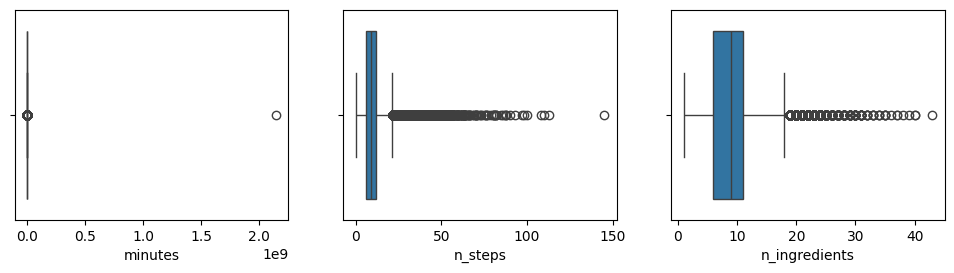

In [21]:
k = 1
plt.figure(figsize=(12, 6))
for i in numerical_columns.columns:
    plt.subplot(2, 3, k)
    sns.boxplot(x=RAW_recipes[i])
    k+=1

Мы можем увидеть большое количество выбросов по количеству шагов и по количеству инградиентов в рецептах, что говорит о том что некоторые рецепты сильно отличаются по этим параметрам от основной массы рецептов

Проведем визуализацию исследовательских данных

In [22]:
RAW_recipes = pd.read_csv('RAW_recipes.csv')
RAW_recipes.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


Text(0, 0.5, 'Количество рецептов')

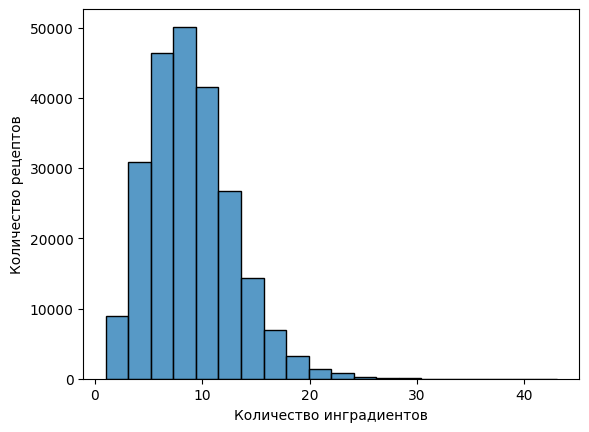

In [23]:
sns.histplot(RAW_recipes.n_ingredients,bins=20, kde=False)
plt.xlabel('Количество инградиентов')
plt.ylabel('Количество рецептов')

показано, что в большинстве рецептов используется около 10 ингредиентов, в то время как есть рецепты с большим количеством ингредиентов, например, до 40.

Text(0, 0.5, 'Количество рецептов')

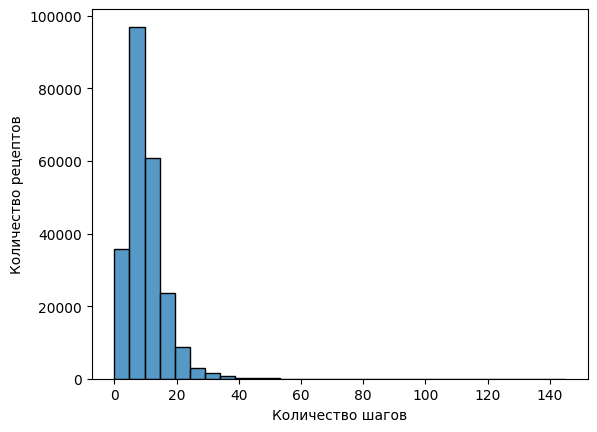

In [24]:
sns.histplot(RAW_recipes.n_steps,bins=30, kde=False)
plt.xlabel('Количество шагов')
plt.ylabel('Количество рецептов')

показано, что большинство рецептов состоят из 20 шагов, в то время как некоторые рецепты могут содержать до 40 шагов.

Создадим корреляционную матрицу

In [25]:
RAW_recipes.corr(numeric_only=True)

,id,minutes,contributor_id,n_steps,n_ingredients
id,1.000000,0.000582,0.114323,0.064512,0.039227
minutes,0.000582,1.000000,-0.000105,-0.000257,-0.000592
contributor_id,0.114323,-0.000105,1.000000,0.038569,0.019602
n_steps,0.064512,-0.000257,0.038569,1.000000,0.427705
n_ingredients,0.039227,-0.000592,0.019602,0.427705,1.000000


Построим тепловую карту взаимосвязи характеристик рецептов

Text(0.5, 1.0, 'Тепловая карта взаимосвязи характеристик рецептов')

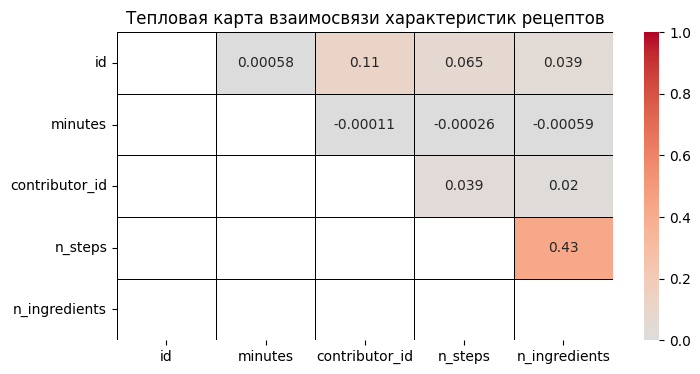

In [26]:
matrix = np.tril(RAW_recipes.corr(numeric_only=True))
plt.figure(figsize=(8,4))
sns.heatmap(RAW_recipes.corr(numeric_only=True),annot=True, fmt='.2g', vmin=0, vmax=1, center=0, cmap='coolwarm', linewidths=0.5, linecolor='black', mask=matrix)
plt.title('Тепловая карта взаимосвязи характеристик рецептов')

Можно сказать, что наблюдается дотаточно сильная взаимосвязь количество шагов приготовления от количества инградиентов

In [27]:
def treat_ingredients(input_list):
    """
    Принимает список ингредиентов (строк).
    Возвращает одну строку, где ингредиенты соединены пробелами,
    а внутренние пробелы заменены на подчеркивания.
    """
    processed_ingredients = []
    for ingredient in input_list:
        # Убираем лишние пробелы по краям и заменяем внутренние на подчеркивания
        # Важно: .strip() убирает пустые строки, если они были
        clean_ingredient = ingredient.strip().replace(' ', '_')
        if clean_ingredient: # Добавляем только если строка не пустая
            processed_ingredients.append(clean_ingredient)
    
    return " ".join(processed_ingredients)

In [28]:
# Преобразуем ингредиенты в нужный нам формат
# ingredients_all - это pandas Series, где каждый элемент может быть строкой или списком
ingredients_all = RAW_recipes.ingredients.apply(lambda x: treat_ingredients(x))

# Токенизируем каждый список ингредиентов.
# Мы разбиваем строку по пробелам, так как treat_ingredients уже заменила внутренние пробелы на подчеркивания.
# Добавим проверку типа данных, чтобы избежать ошибки 'list' object has no attribute 'strip'
tokenized_ingredients = []
for doc in ingredients_all:
    if isinstance(doc, str): # Если это строка
        tokenized_ingredients.append(doc.split())
    elif isinstance(doc, list): # Если это уже список
        tokenized_ingredients.append(doc)
    else:
        # Если это что-то другое (например, NaN), добавляем пустой список
        tokenized_ingredients.append([])

print(f"Пример токенизированных данных: {tokenized_ingredients[0][:10]}...")
print(f"Общее количество документов (рецептов): {len(tokenized_ingredients)}")

Пример токенизированных данных: ['[', "'", 'w', 'i', 'n', 't', 'e', 'r', 's', 'q']...
Общее количество документов (рецептов): 231637


In [29]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\SERGEY\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\SERGEY\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [30]:
# соединим все ингредиенты в один массив
ingredients_corpus = " ".join(list(ingredients_all))

# токенизируем (разбиваем на слова) весь корпус
# .lower() поможет избежать дублирования слов типа "Sugar" и "sugar"
tokens = nltk.word_tokenize(ingredients_corpus.lower())

# Проверим, что получилось
print(f"Всего токенов: {len(tokens)}")
print(f"Примеры токенов: {tokens[:20]}")

Всего токенов: 28553847
Примеры токенов: ['[', "'", 'w', 'i', 'n', 't', 'e', 'r', 's', 'q', 'u', 'a', 's', 'h', "'", ',', "'", 'm', 'e', 'x']


In [31]:
# преобразуем его в частотное распределение с помощью FreqDist
ingre_dist = FreqDist(ingredients_corpus)

In [32]:
# Получим имена инградиентов
ing_key =  list(ingre_dist.keys())

In [33]:
len(ing_key)

52

In [34]:
# создадим кортежи (название ингредиента, частота использования) для последующего использования
ing_freq = []
for key in ing_key:
    ing_freq.append((key,ingre_dist[key]))

ing_freq_sorted = sorted(ing_freq,key = lambda x: x[1],reverse = True)

In [35]:
# Преобразуем данные в датафрйем для визуализации
df_ing = pd.DataFrame(ing_freq_sorted[:20], columns =['Tag', 'Freq'])

C:\Users\SERGEY\AppData\Local\Temp\ipykernel_14552\2063072041.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Freq", y="Tag", data=df_ing,palette="Greens_d",ax = ax)


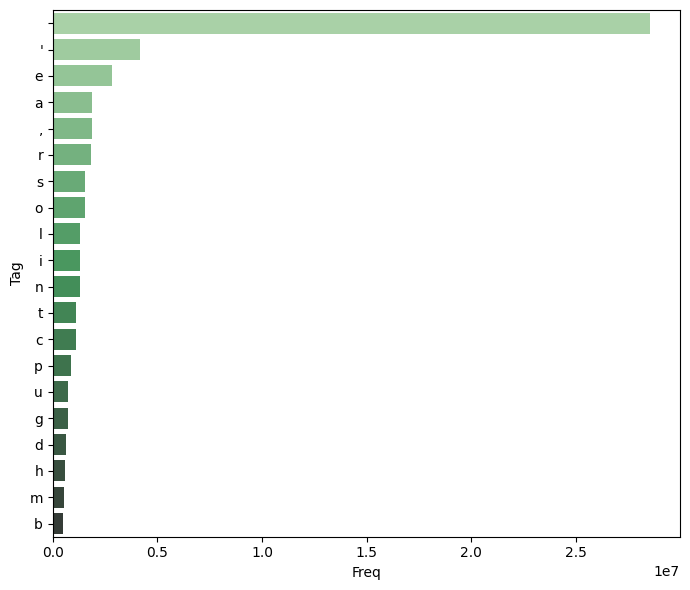

In [36]:
# Визуализируем частотность использования инградиентов в рецептах
f, ax = plt.subplots(figsize=(7, 6))
sns.barplot(x="Freq", y="Tag", data=df_ing,palette="Greens_d",ax = ax)
plt.tight_layout()

Проведем анализ RAW_interactions

In [37]:
RAW_interactions = pd.read_csv('RAW_interactions.csv')
RAW_interactions.head()

,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


**user_id** - уникальный id пользователя

**recipe_id** - уникальный id рецепта

**date** - дата публикации рецепта

**rating** - рейтинг рецепта

**review** -  обзор рецепта

Посмотрим на описание данного датасета

In [38]:
RAW_interactions.describe()

,user_id,recipe_id,rating
count,1.132367e+06,1.132367e+06,1.132367e+06
mean,1.384291e+08,1.608972e+05,4.411016e+00
std,5.014269e+08,1.303987e+05,1.264752e+00
min,1.533000e+03,3.800000e+01,0.000000e+00
25%,1.354700e+05,5.425700e+04,4.000000e+00
50%,3.309370e+05,1.205470e+05,5.000000e+00
75%,8.045500e+05,2.438520e+05,5.000000e+00
max,2.002373e+09,5.377160e+05,5.000000e+00


мы имеем чуть больше миллиона пользователей (1 132 367)

Посмотрим на наличие пропусков

In [39]:
RAW_interactions.isna().mean()

user_id      0.000000
recipe_id    0.000000
date         0.000000
rating       0.000000
review       0.000149
dtype: float64

Пропусков нет

Проведем анализ NaN вхождений

In [40]:
RAW_interactions.isnull().sum()

user_id        0
recipe_id      0
date           0
rating         0
review       169
dtype: int64

Мы получили 169 NaN значений в обзорах рецептов

Определим категориальные и числовые признаки

In [41]:
RAW_interactions.dtypes

user_id      int64
recipe_id    int64
date           str
rating       int64
review         str
dtype: object

In [42]:
RAW_interactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 1132367 entries, 0 to 1132366
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1132367 non-null  int64
 1   recipe_id  1132367 non-null  int64
 2   date       1132367 non-null  str  
 3   rating     1132367 non-null  int64
 4   review     1132198 non-null  str  
dtypes: int64(3), str(2)
memory usage: 43.2 MB


Теперь посмотрим на наличие выбросов по всем числовым признакам. Все что касается id лучше исключить из описательной статистики, так как это не вещественный признак и не проверять на выбросы

In [43]:
RAW_interactions = RAW_interactions.drop(columns=['user_id', 'recipe_id'])
RAW_interactions.head()

,date,rating,review
0,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,2002-12-01,4,This worked very well and is EASY. I used not...
3,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


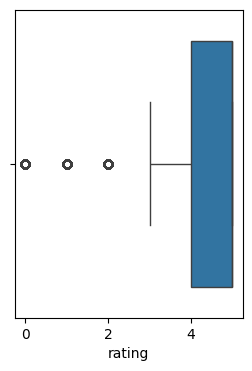

In [44]:
numerical_columns = RAW_interactions.select_dtypes('number')
k = 1
plt.figure(figsize=(10, 4))
for i in numerical_columns.columns:
    plt.subplot(1, 3, k)
    sns.boxplot(x=RAW_interactions[i])
    k+=1

Наблюдается очень небольшое количество выбросов по числовым данным

In [45]:
RAW_interactions = pd.read_csv('RAW_interactions.csv')
RAW_interactions.head()

,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


Text(0, 0.5, 'Количество рецептов')

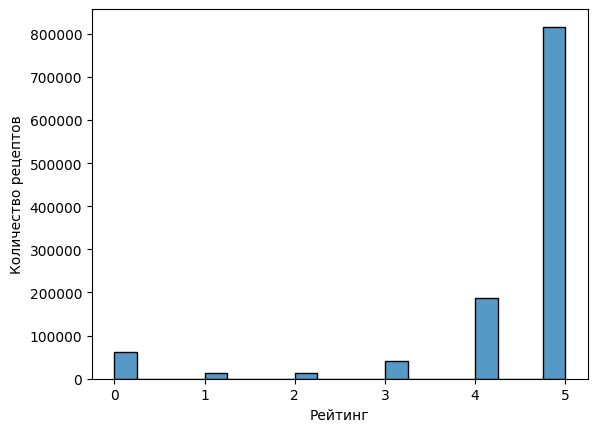

In [46]:
sns.histplot(RAW_interactions.rating,bins=20, kde=False)
plt.xlabel('Рейтинг')
plt.ylabel('Количество рецептов')

Видно , что наибольшее количество рецептов получило максимальный рейтинг (5)

In [47]:
recipe_counts = dict(Counter(RAW_interactions.recipe_id))

In [48]:
import operator
sorted_recipes = sorted(recipe_counts.items(), key=operator.itemgetter(1),reverse = True)

In [49]:
recipes_names = dict([(rep_id,name) for name,rep_id in zip(RAW_recipes.name,RAW_recipes.id)])

In [50]:
def translate_recipe_names(results,rep_names = recipes_names):
    return [pretty_text(rep_names[r]) for r in results]

def pretty_text (text):
    ''' Эта функция принимает текст и пытается перевести его в удобочитаемый формат, вставив обратно \' и сделав его заглавным'''
    text = text.replace(" s ","\'s ")
    text_split = text.split(" ")

    text_split = [t.strip().capitalize() for t in text_split if t != '']

    return " ".join(text_split)

Посмотрим на 10 самых популярных рецептов, основанных на количестве отзывов

In [51]:
n=10
popular_keys = [key[0] for key in sorted_recipes[:n]]
popular_counts = [key[1] for key in sorted_recipes[:n]]

Text(0.5, 0, 'Frequency')

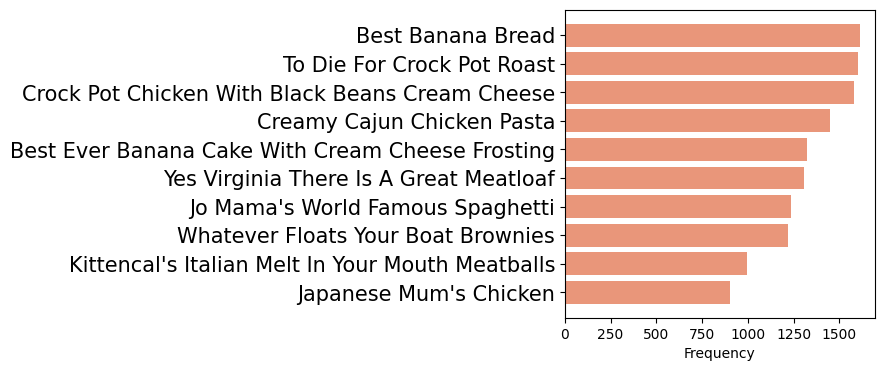

In [52]:
f, ax = plt.subplots(figsize=(4, 4))
ax.barh(range(n), popular_counts[::-1], align='center',color='#E9967A')
ax.set_yticks(range(n))
ax.set_yticklabels(translate_recipe_names(popular_keys[::-1]),fontsize=15)
ax.set_xlabel('Frequency')

In [53]:
recipe_counts = dict(Counter(RAW_interactions.recipe_id))
recipe_df = pd.DataFrame.from_dict(recipe_counts,orient='index').reset_index().rename(columns={'index':'recipe_id',0:'rep_count'})
data_merge = RAW_interactions.merge(recipe_df,how='left',left_on='recipe_id',right_on = 'recipe_id')

In [54]:
mask = data_merge.rep_count > 10

In [55]:
popular_rep = pd.DataFrame(data_merge[mask].groupby('recipe_id').rating.mean())
popular_rep.head()

,rating
recipe_id,
49,4.350000
62,4.681818
66,4.947368
142,4.681818
150,4.583333


Посмотрим на 10 самых популярных рецептов, основанных на рейтинге

In [56]:
popular_rep = popular_rep.sort_values(by=['rating'],ascending = False)

In [57]:
translate_recipe_names(list(popular_rep[:10].index))

["Nif's Grilled Hawaiian Chicken Skewers",
 'Sage And Rosemary Pork Chops',
 'Lemony Shrimp And Potato Cakes With Tricolor Salsa',
 'Chocolate Macadamia Nut Brownies',
 'Fried Scallops For Four',
 'Cucumber Open Faced Sandwiches',
 'Hot Mulled Apple Cider With Apples Orange Cinnamon',
 'Fruit Loops Non Alcoholic Cocktail',
 'Rhubarb Shortbread',
 'Guava Bars']

In [58]:
popular_rep.head(10)

,rating
recipe_id,
379045,5.0
117570,5.0
475907,5.0
117376,5.0
272719,5.0
17111,5.0
395390,5.0
273893,5.0
60385,5.0


Исследуем interactions_test.csv

In [59]:
interactions_test = pd.read_csv('interactions_test.csv')
interactions_test.head()

,user_id,recipe_id,date,rating,u,i
0,8937,44551,2005-12-23,4.0,2,173538
1,56680,126118,2006-10-07,4.0,16,177847
2,349752,219596,2008-04-12,0.0,26,89896
3,628951,82783,2007-11-13,2.0,45,172637
4,92816,435013,2013-07-31,3.0,52,177935


Посмотрим на описание данного датасета

In [60]:
interactions_test.describe()

,user_id,recipe_id,rating,u,i
count,1.245500e+04,12455.000000,12455.000000,12455.000000,12455.000000
mean,2.912689e+07,209323.124528,4.213087,12288.499318,115488.123485
std,2.334357e+08,135001.832923,1.338503,6897.751394,50448.663212
min,1.533000e+03,120.000000,0.000000,2.000000,102.000000
25%,1.698420e+05,94616.000000,4.000000,6428.500000,76904.000000
50%,3.829540e+05,195040.000000,5.000000,12023.000000,127793.000000
75%,8.016370e+05,314928.500000,5.000000,17985.500000,160024.000000
max,2.002255e+09,537716.000000,5.000000,25074.000000,178264.000000


В даннм датасете представлены 12455 рецептов от пользователей

Посмотрим на наличие пропусков

In [61]:
interactions_test.isna().mean()

user_id      0.0
recipe_id    0.0
date         0.0
rating       0.0
u            0.0
i            0.0
dtype: float64

Пропусков нет

Проведем анализ NaN вхождений

In [62]:
interactions_test.isnull().sum()

user_id      0
recipe_id    0
date         0
rating       0
u            0
i            0
dtype: int64

NaN значений нет

Определим категориальные и числовые признаки

In [63]:
interactions_test.dtypes

user_id        int64
recipe_id      int64
date             str
rating       float64
u              int64
i              int64
dtype: object

In [64]:
interactions_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 12455 entries, 0 to 12454
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   user_id    12455 non-null  int64  
 1   recipe_id  12455 non-null  int64  
 2   date       12455 non-null  str    
 3   rating     12455 non-null  float64
 4   u          12455 non-null  int64  
 5   i          12455 non-null  int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 584.0 KB


Теперь посмотрим на наличие выбросов по всем числовым признакам. Все что касается id лучше исключить из описательной статистики, так как это не вещественный признак и не проверять на выбросы

In [65]:
interactions_test = interactions_test.drop(columns=['user_id', 'recipe_id'])
interactions_test.head()

,date,rating,u,i
0,2005-12-23,4.0,2,173538
1,2006-10-07,4.0,16,177847
2,2008-04-12,0.0,26,89896
3,2007-11-13,2.0,45,172637
4,2013-07-31,3.0,52,177935


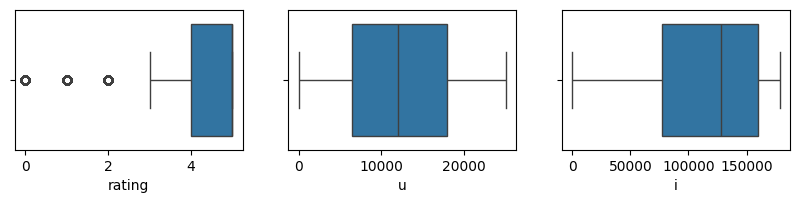

In [66]:
numerical_columns = interactions_test.select_dtypes('number')
k = 1
plt.figure(figsize=(10, 4))
for i in numerical_columns.columns:
    plt.subplot(2, 3, k)
    sns.boxplot(x=interactions_test[i])
    k+=1

Опять наблюдаем минимальное количество выбросов

In [67]:
interactions_test = pd.read_csv('interactions_test.csv')
interactions_test.head()

,user_id,recipe_id,date,rating,u,i
0,8937,44551,2005-12-23,4.0,2,173538
1,56680,126118,2006-10-07,4.0,16,177847
2,349752,219596,2008-04-12,0.0,26,89896
3,628951,82783,2007-11-13,2.0,45,172637
4,92816,435013,2013-07-31,3.0,52,177935


Проведем визуализацию исследований

Text(0, 0.5, 'Количество рецептов')

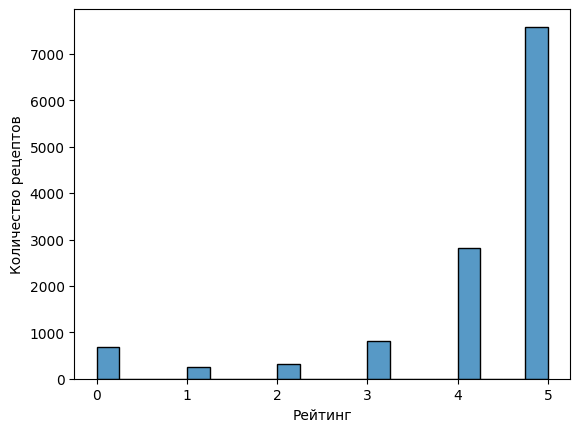

In [68]:
sns.histplot(interactions_test.rating,bins=20, kde=False)
plt.xlabel('Рейтинг')
plt.ylabel('Количество рецептов')

Основное количество рецептов имеет максимальный рейтинг

Создадим корреляционную матрицу

In [69]:
interactions_test.corr(numeric_only=True)

,user_id,recipe_id,rating,u,i
user_id,1.000000,0.152879,-0.036236,0.039711,-0.042208
recipe_id,0.152879,1.000000,0.007018,0.018987,0.026469
rating,-0.036236,0.007018,1.000000,-0.027399,0.014186
u,0.039711,0.018987,-0.027399,1.000000,-0.163622
i,-0.042208,0.026469,0.014186,-0.163622,1.000000


Text(0.5, 1.0, 'Тепловая карта взаимосвязи характеристик рецептов')

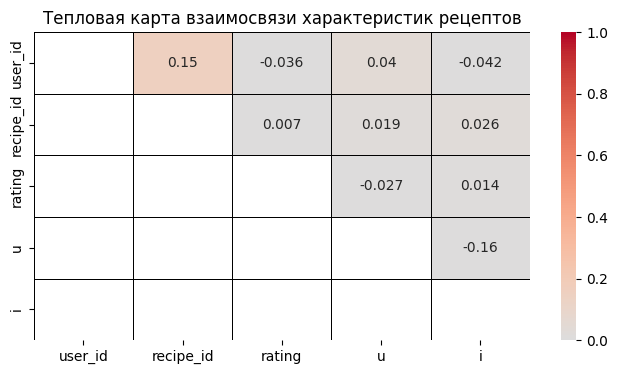

In [70]:
matrix = np.tril(interactions_test.corr(numeric_only=True))
plt.figure(figsize=(8,4))
sns.heatmap(interactions_test.corr(numeric_only=True),annot=True, fmt='.2g', vmin=0, vmax=1, center=0, cmap='coolwarm', linewidths=0.5, linecolor='black', mask=matrix)
plt.title('Тепловая карта взаимосвязи характеристик рецептов')

Посмотрим на функцию рассеяния и плотности

Text(0.5, 1.0, 'Диаграмма рассеяния')

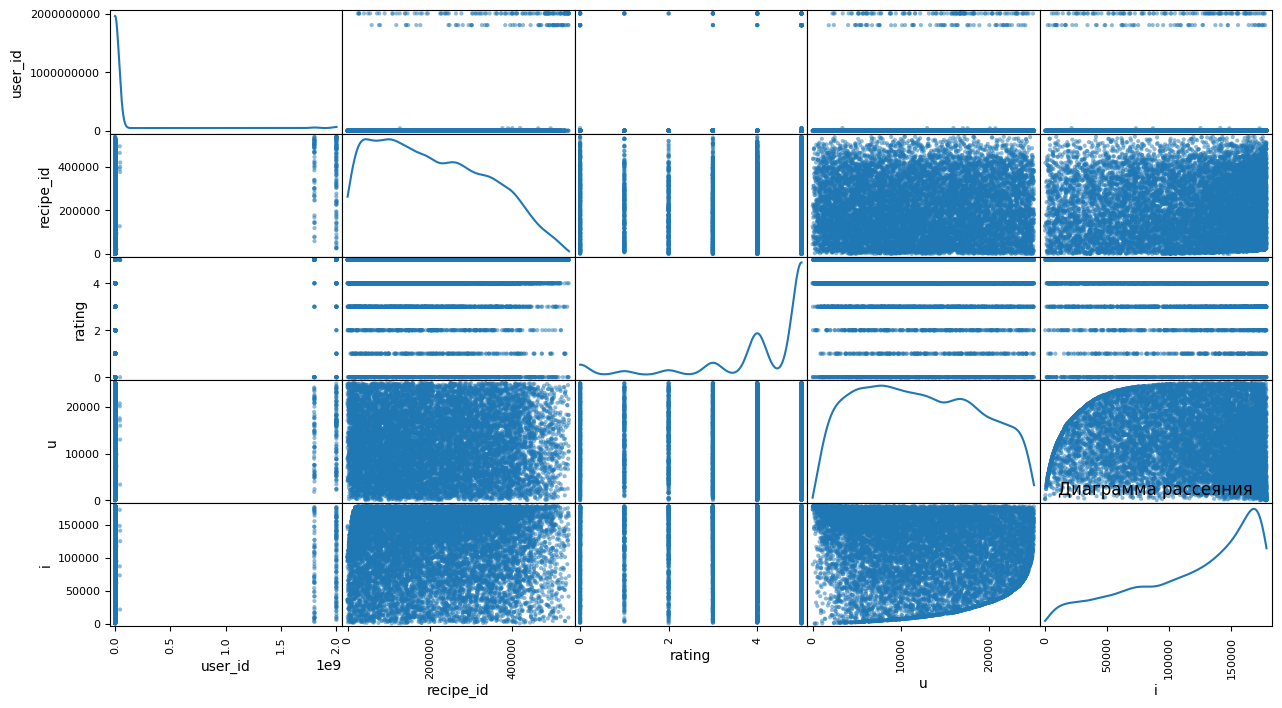

In [71]:
pd.plotting.scatter_matrix(interactions_test, diagonal='kde', figsize=(15,8))
plt.title('Диаграмма рассеяния')

Исследуем теперь файл interactions_train.csv

In [72]:
interactions_train = pd.read_csv('interactions_train.csv')
interactions_train.head()

,user_id,recipe_id,date,rating,u,i
0,2046,4684,2000-02-25,5.0,22095,44367
1,2046,517,2000-02-25,5.0,22095,87844
2,1773,7435,2000-03-13,5.0,24732,138181
3,1773,278,2000-03-13,4.0,24732,93054
4,2046,3431,2000-04-07,5.0,22095,101723


Посмотрим на описание данного датасета

In [73]:
interactions_train.describe()

,user_id,recipe_id,rating,u,i
count,6.989010e+05,698901.000000,698901.000000,698901.000000,698901.000000
mean,1.247694e+07,156173.409849,4.574090,4249.330271,87519.330993
std,1.525031e+08,126594.880211,0.959022,5522.602821,51290.370370
min,1.533000e+03,38.000000,0.000000,0.000000,0.000000
25%,1.059880e+05,53169.000000,4.000000,455.000000,42988.000000
50%,2.301020e+05,116484.000000,5.000000,1737.000000,87424.000000
75%,4.801950e+05,234516.000000,5.000000,5919.000000,131731.000000
max,2.002313e+09,537458.000000,5.000000,25075.000000,178262.000000


В даннм датасете представлено 698901 пользователь и столько же рецептов

Посмотрим на наличие пропусков

In [74]:
interactions_train.isna().mean()

user_id      0.0
recipe_id    0.0
date         0.0
rating       0.0
u            0.0
i            0.0
dtype: float64

Пропусков нет

Проведем анализ NaN вхождений

In [75]:
interactions_train.isnull().sum()

user_id      0
recipe_id    0
date         0
rating       0
u            0
i            0
dtype: int64

NaN значений нет

Определим категориальные и числовые признаки

In [76]:
interactions_train.dtypes

user_id        int64
recipe_id      int64
date             str
rating       float64
u              int64
i              int64
dtype: object

In [77]:
interactions_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 12455 entries, 0 to 12454
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   user_id    12455 non-null  int64  
 1   recipe_id  12455 non-null  int64  
 2   date       12455 non-null  str    
 3   rating     12455 non-null  float64
 4   u          12455 non-null  int64  
 5   i          12455 non-null  int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 584.0 KB


Теперь посмотрим на наличие выбросов по всем числовым признакам. Все что касается id лучше исключить из описательной статистики, так как это не вещественный признак и не проверять на выбросы

In [78]:
interactions_train = interactions_train.drop(columns=['user_id', 'recipe_id'])
interactions_train.head()

,date,rating,u,i
0,2000-02-25,5.0,22095,44367
1,2000-02-25,5.0,22095,87844
2,2000-03-13,5.0,24732,138181
3,2000-03-13,4.0,24732,93054
4,2000-04-07,5.0,22095,101723


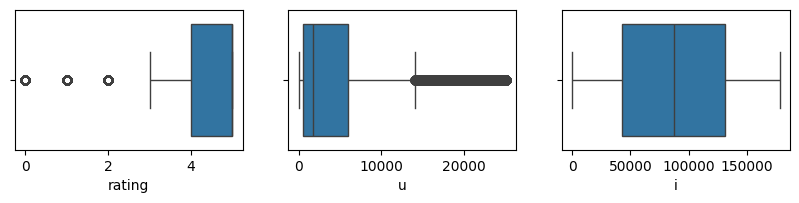

In [79]:
numerical_columns = interactions_train.select_dtypes('number')
k = 1
plt.figure(figsize=(10, 4))
for i in numerical_columns.columns:
    plt.subplot(2, 3, k)
    sns.boxplot(x=interactions_train[i])
    k+=1

наблюдаются выбросы для u

Проведем визуализацию исследований

In [80]:
interactions_train = pd.read_csv('interactions_train.csv')
interactions_train.head()

,user_id,recipe_id,date,rating,u,i
0,2046,4684,2000-02-25,5.0,22095,44367
1,2046,517,2000-02-25,5.0,22095,87844
2,1773,7435,2000-03-13,5.0,24732,138181
3,1773,278,2000-03-13,4.0,24732,93054
4,2046,3431,2000-04-07,5.0,22095,101723


Text(0, 0.5, 'Количество рецептов')

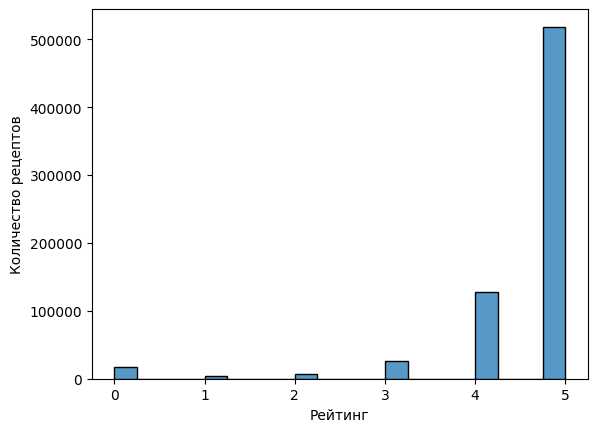

In [81]:
sns.histplot(interactions_train.rating,bins=20, kde=False)
plt.xlabel('Рейтинг')
plt.ylabel('Количество рецептов')

Основное количество рецептов имеет максимальный рейтинг

Создадим корреляционную матрицу

In [82]:
interactions_train.corr(numeric_only=True)

,user_id,recipe_id,rating,u,i
user_id,1.000000,0.011153,-0.033903,0.067255,-0.001047
recipe_id,0.011153,1.000000,0.029262,-0.213752,0.020976
rating,-0.033903,0.029262,1.000000,-0.066059,0.003686
u,0.067255,-0.213752,-0.066059,1.000000,0.025982
i,-0.001047,0.020976,0.003686,0.025982,1.000000


Text(0.5, 1.0, 'Тепловая карта взаимосвязи характеристик рецептов')

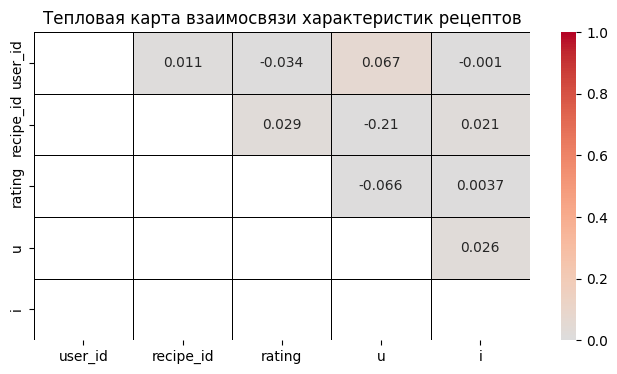

In [83]:
matrix = np.tril(interactions_train.corr(numeric_only=True))
plt.figure(figsize=(8,4))
sns.heatmap(interactions_train.corr(numeric_only=True),annot=True, fmt='.2g', vmin=0, vmax=1, center=0, cmap='coolwarm', linewidths=0.5, linecolor='black', mask=matrix)
plt.title('Тепловая карта взаимосвязи характеристик рецептов')

Посмотрим на функцию рассеяния и плотности

Text(0.5, 1.0, 'Диаграмма рассеяния')

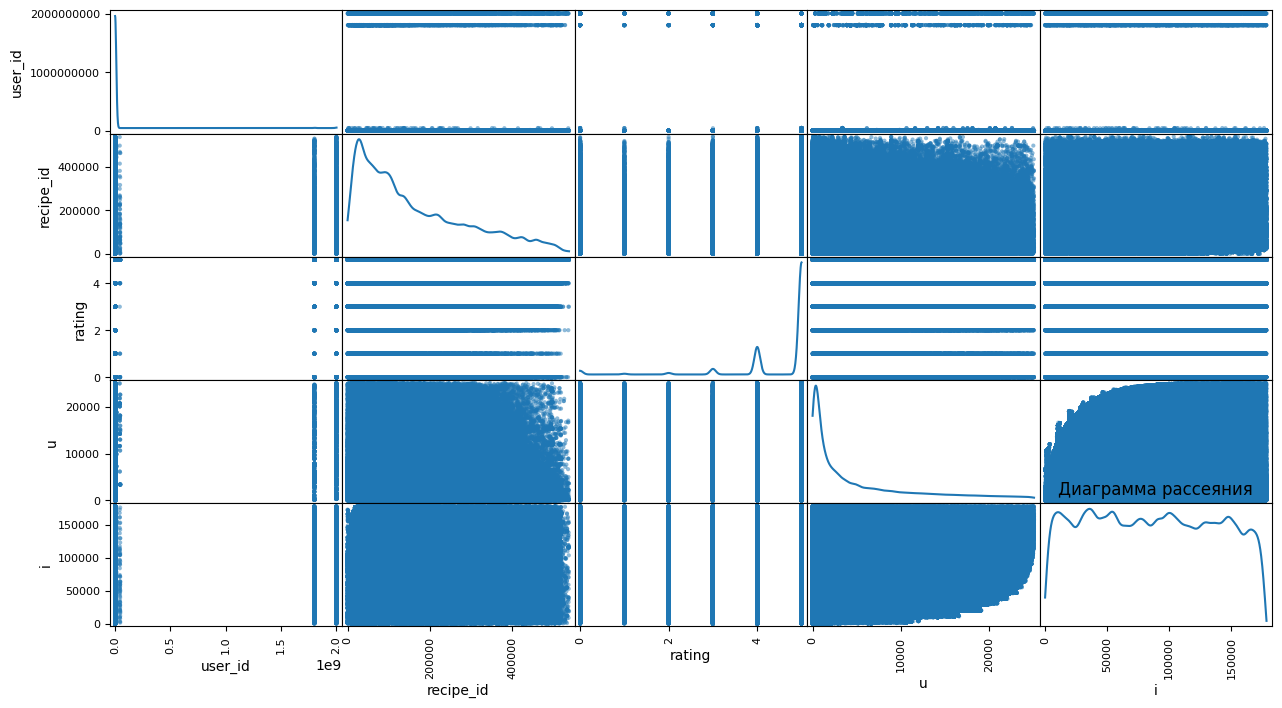

In [84]:
pd.plotting.scatter_matrix(interactions_train, diagonal='kde', figsize=(15,8))
plt.title('Диаграмма рассеяния')

Теперь настала очередь interactions_validation.csv

In [85]:
interactions_validation = pd.read_csv('interactions_validation.csv')
interactions_validation.head()

,user_id,recipe_id,date,rating,u,i
0,76535,33627,2005-02-15,4.0,5,177317
1,160497,75307,2005-10-24,4.0,23,170785
2,930021,100961,2008-11-30,4.0,31,165555
3,58439,154105,2007-03-24,4.0,44,177453
4,628951,14525,2008-02-16,5.0,45,142367


Посмотрим на описание данного датасета

In [86]:
interactions_validation.describe()

,user_id,recipe_id,rating,u,i
count,7.023000e+03,7023.000000,7023.000000,7023.000000,7023.000000
mean,1.947787e+07,206406.038018,4.232806,10298.033746,100122.151075
std,1.904689e+08,135238.437354,1.302910,6709.501293,52051.115779
min,1.533000e+03,120.000000,0.000000,5.000000,144.000000
25%,1.591190e+05,89851.500000,4.000000,4569.500000,56227.000000
50%,3.528340e+05,192146.000000,5.000000,9248.000000,104819.000000
75%,7.373315e+05,311632.500000,5.000000,15637.500000,146690.500000
max,2.002227e+09,536464.000000,5.000000,25055.000000,178263.000000


В даннм датасете представлены 7023 рецептов от пользователей

Посмотрим на наличие пропусков

In [87]:
interactions_validation.isna().mean()

user_id      0.0
recipe_id    0.0
date         0.0
rating       0.0
u            0.0
i            0.0
dtype: float64

Пропусков нет

Проведем анализ NaN вхождений

In [88]:
interactions_validation.isnull().sum()

user_id      0
recipe_id    0
date         0
rating       0
u            0
i            0
dtype: int64

NaN значений нет

Определим категориальные и числовые признаки

In [89]:
interactions_validation.dtypes

user_id        int64
recipe_id      int64
date             str
rating       float64
u              int64
i              int64
dtype: object

In [90]:
interactions_validation.info()

<class 'pandas.DataFrame'>
RangeIndex: 7023 entries, 0 to 7022
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   user_id    7023 non-null   int64  
 1   recipe_id  7023 non-null   int64  
 2   date       7023 non-null   str    
 3   rating     7023 non-null   float64
 4   u          7023 non-null   int64  
 5   i          7023 non-null   int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 329.3 KB


Теперь посмотрим на наличие выбросов по всем числовым признакам. Все что касается id лучше исключить из описательной статистики, так как это не вещественный признак и не проверять на выбросы

In [91]:
interactions_validation = interactions_validation.drop(columns=['user_id', 'recipe_id'])
interactions_validation.head()

,date,rating,u,i
0,2005-02-15,4.0,5,177317
1,2005-10-24,4.0,23,170785
2,2008-11-30,4.0,31,165555
3,2007-03-24,4.0,44,177453
4,2008-02-16,5.0,45,142367


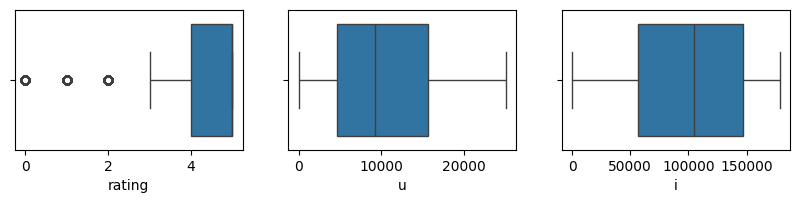

In [92]:
numerical_columns = interactions_validation.select_dtypes('number')
k = 1
plt.figure(figsize=(10, 4))
for i in numerical_columns.columns:
    plt.subplot(2, 3, k)
    sns.boxplot(x=interactions_validation[i])
    k+=1

Опять наблюдаем минимальное количество выбросов

Проведем визуализацию исследований

In [93]:
interactions_validation = pd.read_csv('interactions_validation.csv')
interactions_validation.head()

,user_id,recipe_id,date,rating,u,i
0,76535,33627,2005-02-15,4.0,5,177317
1,160497,75307,2005-10-24,4.0,23,170785
2,930021,100961,2008-11-30,4.0,31,165555
3,58439,154105,2007-03-24,4.0,44,177453
4,628951,14525,2008-02-16,5.0,45,142367


Text(0, 0.5, 'Количество рецептов')

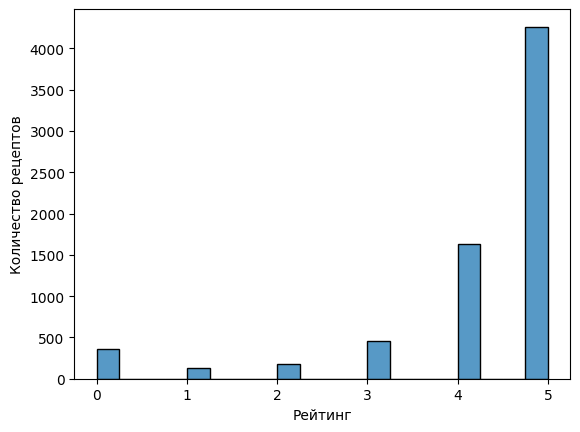

In [94]:
sns.histplot(interactions_validation.rating,bins=20, kde=False)
plt.xlabel('Рейтинг')
plt.ylabel('Количество рецептов')

Основное количество рецептов имеет максимальный рейтинг

Создадим корреляционную матрицу

In [95]:
interactions_validation.corr(numeric_only=True)

,user_id,recipe_id,rating,u,i
user_id,1.000000,0.138600,-0.039084,0.027926,-0.031898
recipe_id,0.138600,1.000000,-0.004041,-0.004686,0.008899
rating,-0.039084,-0.004041,1.000000,-0.050295,0.049429
u,0.027926,-0.004686,-0.050295,1.000000,-0.202281
i,-0.031898,0.008899,0.049429,-0.202281,1.000000


Text(0.5, 1.0, 'Тепловая карта взаимосвязи характеристик рецептов')

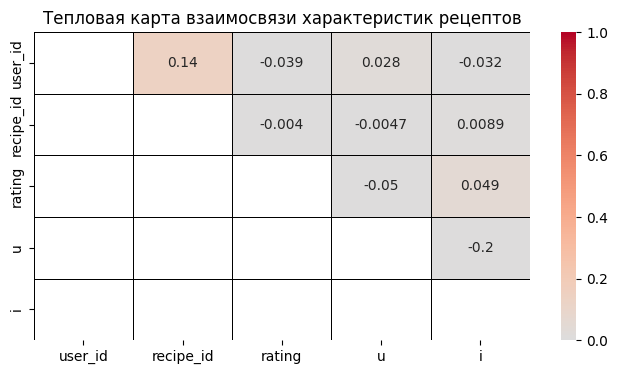

In [96]:
matrix = np.tril(interactions_validation.corr(numeric_only=True))
plt.figure(figsize=(8,4))
sns.heatmap(interactions_validation.corr(numeric_only=True),annot=True, fmt='.2g', vmin=0, vmax=1, center=0, cmap='coolwarm', linewidths=0.5, linecolor='black', mask=matrix)
plt.title('Тепловая карта взаимосвязи характеристик рецептов')

Посмотрим на функцию рассеяния и плотности

Text(0.5, 1.0, 'Диаграмма рассеяния')

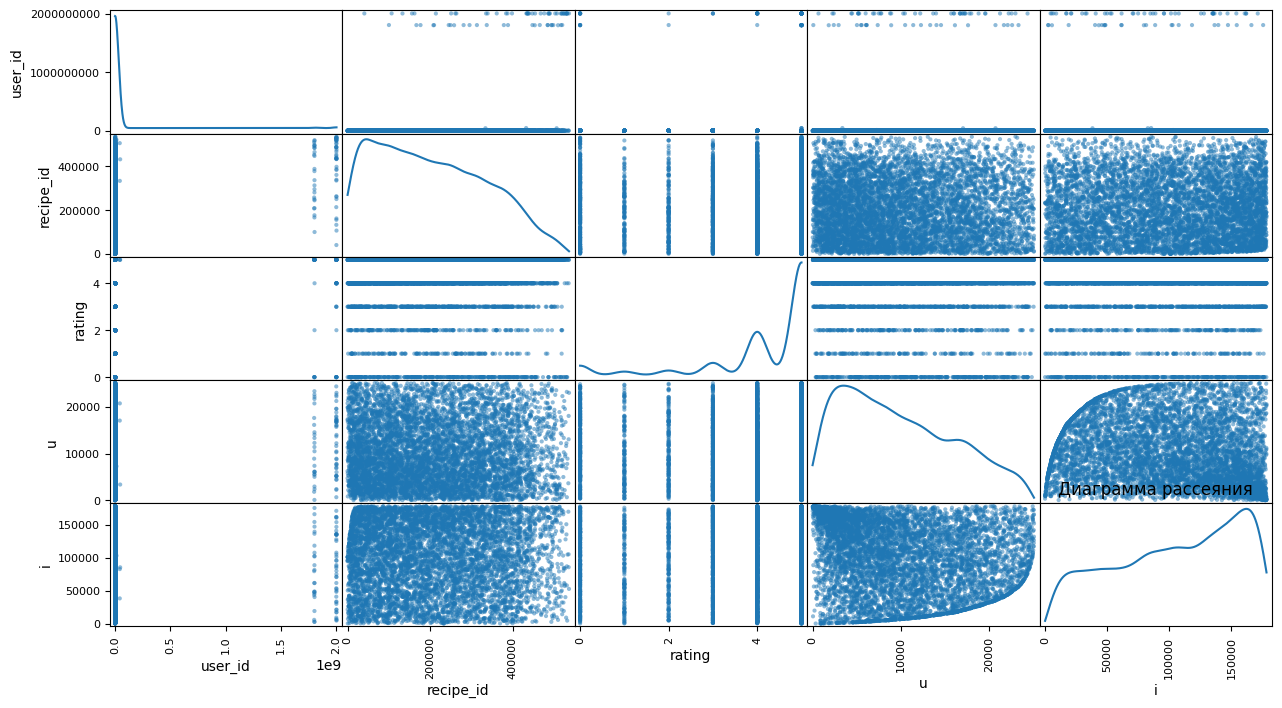

In [97]:
pd.plotting.scatter_matrix(interactions_validation, diagonal='kde', figsize=(15,8))
plt.title('Диаграмма рассеяния')

**LDA-система рекомендаций на основе контента.
 Преобразуем рецепты с использованием технологии LDA для извлечения тем и используем совместную фильтрацию для выявления похожих рецептов для рекомендации **

In [98]:
import random
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

seed = 0

In [99]:
RAW_recipes = pd.read_csv('RAW_recipes.csv')
RAW_recipes.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


In [100]:
data = RAW_recipes

In [101]:
def treat_ingredients(ing_list):
    output = []
    for ingredient in ing_list:
        ingredient_list = ingredient.split(' ')
        output.append("_".join(ingredient_list))
    return output

In [102]:
def get_similarity(lda, query_vector):
    index = similarities.MatrixSimilarity(lda[corpus])
    sims = index[query_vector]
    return sims

In [103]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# --- Шаг 1: Векторизация текста ---
# Сначала подготовим список документов (строк) для векторизатора
# и отфильтруем пустые строки, чтобы избежать ошибки empty vocabulary
documents = []
for doc in tokenized_ingredients:
    # Если doc - это список (как в вашем коде), склеиваем его
    if isinstance(doc, list):
        text = ' '.join(doc)
    else:
        text = str(doc)
    
    # Добавляем в список только непустые строки
    if text.strip():
        documents.append(text)

print(f"Количество непустых документов для обучения LDA: {len(documents)}")

# Теперь создаем векторизатор
# token_pattern = r"(?u)\b\w+\b" заставляет распознавать слова любой длины (включая однобуквенные)
vectorizer = CountVectorizer(
    max_df=0.95, 
    min_df=5, 
    stop_words='english',
    token_pattern=r"(?u)\b\w+\b"  # <--- Добавлен этот параметр
)

# Обучаем векторизатор на очищенных данных
doc_term_matrix = vectorizer.fit_transform(documents)

print(f"Размер матрицы 'документ-термин': {doc_term_matrix.shape}")

# --- Шаг 2: Обучение LDA модели ---
num_topics = 20
lda_model = LatentDirichletAllocation(n_components=num_topics,
                                      max_iter=10,
                                      learning_method='online',
                                      random_state=42)

# Обучаем модель
lda_model.fit(doc_term_matrix)

print("LDA модель успешно обучена.")

# --- Шаг 3: Просмотр тем ---
def print_top_words(model, feature_names, n_top_words):
    for topic_idx, topic in enumerate(model.components_):
        message = "Тема #%d: " % topic_idx
        message += " ".join([feature_names[i] for i in topic.argsort()[:-n_top_words - 1:-1]])
        print(message)
    print()

# Получаем названия всех ингредиентов из векторизатора
tf_feature_names = vectorizer.get_feature_names_out()

# Печатаем топ-10 слов для каждой темы
print_top_words(lda_model, tf_feature_names, 10)

Количество непустых документов для обучения LDA: 231637
Размер матрицы 'документ-термин': (231637, 26)
LDA модель успешно обучена.
Тема #0: z f m g p u h b d v
Тема #1: 3 4 m b g u d v k p
Тема #2: u g m d b k f p w v
Тема #3: d p g w m u y h v k
Тема #4: x v m d k g w f u p
Тема #5: 9 8 u h f p m g d b
Тема #6: h k m y v d p f u b
Тема #7: 2 f w k m p d g v h
Тема #8: f h m v p g y u d b
Тема #9: d h m u b f p g k w
Тема #10: g u w p b h d k f m
Тема #11: 6 h g f b q d u w m
Тема #12: 7 u p d q f k w m y
Тема #13: j u m y p v f g d h
Тема #14: p m h u g d w y v k
Тема #15: 5 b u m k g d p h v
Тема #16: v g b m d u h y p k
Тема #17: y u w b h m f g d v
Тема #18: 1 0 f k m w u d g b
Тема #19: p b u k d h g f y m



In [104]:
sample_w = "butter, salt, pepper"

In [105]:
# определим входную функцию treat_words, возвращающую список маркированных ингредиентов
def treat_words (words):
    list_words = words.split(",")
    output = []
    for w in list_words:
        output.append("_".join(w.strip().split(" ")))
    return output

In [106]:
def calculate_similarity(query,ldamodel,dct):
    # обработаем вводимые слова
    words_bow = dct.doc2bow(treat_words(query))
    query_vector = ldamodel[words_bow]

    # рассчитаем рейтинг
    sim_rank = get_similarity(lda = ldamodel, query_vector = query_vector)
    sim_rank = sorted(enumerate(sim_rank), key=lambda item: -item[1])

    return sim_rank

In [107]:
def calculate_recommendation(sim_rank,groups,n_reco = 10):
    results = [sim_rank[0][0]]
    results_prob = [sim_rank[0][1]]
    result_group = [sim_rank[0][1]]

    for recipe,group in zip(sim_rank[1:],groups[1:]):
        if group not in set(result_group):
            results.append(recipe[0])
            result_group.append(group)
            results_prob.append(recipe[1])
        if len(results) == n_reco:
            break
    print(result_group,"\n",results_prob)
    return results

In [108]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def get_similarity_reco(query, lda_model, dct, corpus, n_reco=10):
    """
    Поиск похожих рецептов на основе тематической близости (sklearn LDA).
    
    Параметры:
    query — строка или список токенов (ингредиенты)
    lda_model — обученная модель LatentDirichletAllocation из sklearn
    dct — SklearnDictionaryWrapper (наш словарь-обертка)
    corpus — список документов (bag-of-words) — не используется, но оставлен для совместимости
    n_reco — сколько рекомендаций вернуть
    
    Возвращает: список индексов документов (в порядке убывания схожести)
    """
    
    # 1. Приводим запрос к списку токенов
    if isinstance(query, str):
        query_tokens = query.lower().split()
    else:
        query_tokens = [t.lower() for t in query]

    # 2. Получаем bag-of-words запроса через наш wrapper
    query_bow = dct.doc2bow(query_tokens)
    
    if len(query_bow) == 0:
        print("Запрос не содержит известных модели токенов.")
        return []

    # 3. Преобразуем запрос в вектор признаков (CountVectorizer)
    #    Нам нужен сам vectorizer, он лежит внутри wrapper'а
    vectorizer = dct.vectorizer
    
    # Формируем строку запроса так же, как при обучении
    query_str = ' '.join(query_tokens)
    query_vec = vectorizer.transform([query_str])  # shape (1, n_features)

    # 4. Получаем тематическое распределение запроса через sklearn
    query_topic = lda_model.transform(query_vec)[0]  # shape (n_topics,)

    # 5. Получаем тематическое распределение всего корпуса
    #    (лучше один раз посчитать заранее, но для наглядности считаем здесь)
    #    ingredients_strings — это глобальная переменная из ячейки 28
    global ingredients_strings
    corpus_matrix = vectorizer.transform(ingredients_strings)
    doc_topics = lda_model.transform(corpus_matrix)  # shape (n_docs, n_topics)

    # 6. Считаем косинусную близость между запросом и каждым документом
    #    cosine_similarity вернет матрицу (1, n_docs), берем первую строку
    sims = cosine_similarity(query_topic.reshape(1, -1), doc_topics)[0]

    # 7. Находим топ-N индексов
    top_idx = np.argsort(sims)[::-1][:n_reco]

    # 8. Возвращаем список индексов (функция calculate_recommendation ожидает индексы)
    return top_idx.tolist()

In [109]:
def print_reco(indices, recipes_df):
    """
    Принимает список индексов и DataFrame с рецептами,
    выводит названия рецептов по этим индексам.
    """
    if not indices:
        print("Рекомендации не найдены.")
        return

    print(f"--- Топ {len(indices)} рекомендаций: ---")
    for i, idx in enumerate(indices):
        try:
            # Используем .iloc для доступа по позиционному индексу
            # Это работает, потому что recipes_df - это DataFrame
            recipe_name = recipes_df.iloc[idx]['name']
            print(f"{i+1}. {recipe_name}")
        except IndexError:
            print(f"{i+1}. [Ошибка: индекс {idx} вне диапазона DataFrame]")
        except Exception as e:
            print(f"{i+1}. [Ошибка при получении названия: {e}]")
    print("------------------------------------")

In [110]:
def print_reco(results, recipes_df):
    """
    Выводит названия рекомендованных рецептов.
    
    results: список индексов (id) рецептов.
    recipes_df: DataFrame, содержащий информацию о рецептах (например, RAW_recipes).
    """
    print("Рекомендованные рецепты:")
    for i, idx in enumerate(results):
        try:
            # Получаем название рецепта по его индексу
            recipe_name = recipes_df.iloc[idx]['name']
            # Используем функцию pretty_name, если она у вас уже определена
            # Если нет, можно просто вывести имя
            print(f"{i+1}. {recipe_name}")
        except IndexError:
            print(f"{i+1}. [Ошибка: индекс {idx} вне диапазона DataFrame]")
        except Exception as e:
            print(f"{i+1}. [Ошибка при получении названия: {e}]")
    print("-" * 30)

In [111]:
def pretty_name (name):
    return " ".join([ word.capitalize() for word in name.split(" ") if word != ""])

Приведенный ниже код обучает модель LDA, которая содержит 10 тем. Наш алгоритм попытается порекомендовать варианты из разных групп. Чтобы у пользователей не было одинаковых рекомендаций

In [112]:
# 1. Функция train_lda_model
def train_lda_model(doc_term_matrix, num_topics=10, passes=10):
    from sklearn.decomposition import LatentDirichletAllocation
    lda = LatentDirichletAllocation(
        n_components=num_topics,
        max_iter=passes,
        learning_method='online',
        random_state=42
    )
    lda.fit(doc_term_matrix)
    return lda

# 2. Проверка данных: ingredients_all — это Series со СПИСКАМИ токенов
if 'ingredients_all' not in locals():
    # fallback: если ячейка 105 не выполнялась
    ingredients_all = RAW_recipes.ingredients.apply(lambda x: treat_ingredients(x))

# Превращаем Series в список списков строк
tokenized_docs = []
for doc in ingredients_all:
    if isinstance(doc, list):
        tokenized_docs.append([str(t) for t in doc])
    elif isinstance(doc, str):
        tokenized_docs.append(doc.split())
    else:
        tokenized_docs.append([])

print("Пример документа (токены):", tokenized_docs[0][:10])
print("Всего документов:", len(tokenized_docs))

# 3. Векторизация: analyzer=lambda x: x — значит, "вход уже токенизирован"
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=5,
    analyzer=lambda x: x,      # <-- ключевой момент
    token_pattern=None          # игнорируется при analyzer
)

doc_term_matrix = vectorizer.fit_transform(tokenized_docs)
print(f"Размер матрицы: {doc_term_matrix.shape}")

# 4. Обучение LDA
lda_model = train_lda_model(doc_term_matrix, num_topics=10, passes=10)
print("LDA модель обучена.")

# 5. Печать топ-слов
def print_top_words(model, feature_names, n_top_words=10):
    for topic_idx, topic in enumerate(model.components_):
        message = "Тема #%d: " % topic_idx
        message += " ".join([feature_names[i] for i in topic.argsort()[:-n_top_words - 1:-1]])
        print(message)

tf_feature_names = vectorizer.get_feature_names_out()
print_top_words(lda_model, tf_feature_names, 10)


Пример документа (токены): ['[', "'", 'w', 'i', 'n', 't', 'e', 'r', 's', 'q']
Всего документов: 231637
Размер матрицы: (231637, 32)
LDA модель обучена.
Тема #0: % 1 9 8 0 5 7 3 4 k
Тема #1: j u m q f p h v d y
Тема #2: h p m d u g f b k v
Тема #3: x " v f m ! u g k w
Тема #4: - f p u d h w 6 g k
Тема #5: g u b d p m w k f h
Тема #6: h w u b y m g f k v
Тема #7: p g d b h u k y m w
Тема #8: d m w u g y p h v k
Тема #9: z f m g p u 2 ! h d


In [113]:
# Предположим, что lda_model уже обучена на doc_term_matrix
# и у нас есть список индексов рецептов, которые мы хотим показать.
# Например, возьмем первые 5 рецептов из матрицы.
# В реальной задаче здесь должны быть индексы, полученные из модели рекомендаций.

# Для примера возьмем индексы первых 5 строк матрицы
example_recommendations = list(range(5)) 

# Вызываем функцию, передавая ей список индексов и DataFrame с рецептами
print_reco(example_recommendations, RAW_recipes)

Рекомендованные рецепты:
1. arriba   baked winter squash mexican style
2. a bit different  breakfast pizza
3. all in the kitchen  chili
4. alouette  potatoes
5. amish  tomato ketchup  for canning
------------------------------


In [114]:
query = 'Butter Madeira Cake, Cheese Rolls, Chicken Breasts Saltimbocca, Swiss Crab Melt'

In [123]:
# 1. Импортируем все необходимое
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 2. Проверяем наличие ключевых переменных из предыдущих ячеек
if 'RAW_recipes' not in globals():
    raise NameError("ОШИБКА: Переменная 'RAW_recipes' не найдена. Убедитесь, что предыдущие ячейки выполнены.")
if 'lda_model' not in globals():
    raise NameError("ОШИБКА: Переменная 'lda_model' не найдена. Убедитесь, что ячейка с обучением модели выполнена.")
if 'query' not in globals():
    raise NameError("ОШИБКА: Переменная 'query' не найдена. Убедитесь, что ячейка с ее созданием выполнена.")

print("Все необходимые переменные найдены. Начинаем подготовку данных...")

# 3. Создаем tokenized_ingredients заново, чтобы гарантировать правильный формат
# (список списков токенов) для текущей сессии.
def treat_ingredients(input_list):
    """Принимает список ингредиентов, возвращает строку с токенами, разделенными пробелами."""
    processed_ingredients = []
    for ingredient in input_list:
        # Убираем лишние пробелы и заменяем внутренние на подчеркивания
        clean_ingredient = ingredient.strip().replace(' ', '_')
        if clean_ingredient:
            processed_ingredients.append(clean_ingredient)
    return " ".join(processed_ingredients)

ingredients_all = RAW_recipes.ingredients.apply(lambda x: treat_ingredients(x))
tokenized_ingredients = [doc.split() for doc in ingredients_all]
print(f"Переменная 'tokenized_ingredients' создана. Пример: {tokenized_ingredients[0][:5]}...")

# 4. Создаем corpus и правильный dictionary с помощью CountVectorizer
# Это ключевой момент для исправления ошибки.
documents = [' '.join(doc) for doc in tokenized_ingredients]
vectorizer = CountVectorizer(lowercase=False, token_pattern=r"(?u)\b\w+\b")
corpus_matrix = vectorizer.fit_transform(documents)
corpus = corpus_matrix

# 5. Создаем класс-обертку, который имеет метод doc2bow
# Это именно то, что ожидает ваша функция get_similarity_reco.
class DictionaryWrapper:
    def __init__(self, vectorizer):
        self.vectorizer = vectorizer
        self.token2id = vectorizer.vocabulary_

    def doc2bow(self, tokens):
        """
        Преобразует список токенов в "мешок слов" (bag-of-words) формат,
        который понимает LDA-модель. Формат: [(word_id, count), ...]
        """
        # Считаем частоту каждого токена
        token_counts = pd.Series(tokens).value_counts()
        bow = []
        for token, count in token_counts.items():
            # Если токен есть в словаре векторизатора, добавляем его ID и частоту
            if token in self.token2id:
                bow.append((self.token2id[token], count))
        return bow

# Создаем экземпляр нашей обертки
dictionary_wrapper = DictionaryWrapper(vectorizer)
print(f"Corpus и словарь успешно созданы. Размер матрицы: {corpus.shape}")


# 6. Вызываем функцию get_similarity_reco и печатаем результаты
try:
    # Проверяем, существует ли сама функция
    if 'get_similarity_reco' not in globals():
        raise NameError("Функция 'get_similarity_reco' не определена. Убедитесь, что ячейка с ее определением выполнена.")
    if 'print_reco' not in globals():
        raise NameError("Функция 'print_reco' не определена. Убедитесь, что ячейка с ее определением выполнена.")

    print("\nВызов функции get_similarity_reco...")
    results = get_similarity_reco(
        query,
        lda_model,
        dictionary_wrapper,
        corpus=corpus,
        n_reco=10
    )
    
    print("Рекомендации успешно сформированы:")
    print_reco(results, RAW_recipes)

except NameError as e:
    print(f"\nОШИБКА: {e}")
    print("Пожалуйста, убедитесь, что все предыдущие ячейки, определяющие эти функции и переменные, были выполнены.")
except Exception as e:
    print(f"\nПроизошла непредвиденная ошибка при вызове функции: {e}")
    import traceback
    traceback.print_exc()



Все необходимые переменные найдены. Начинаем подготовку данных...
Переменная 'tokenized_ingredients' создана. Пример: ['[', "'", 'w', 'i', 'n']...
Corpus и словарь успешно созданы. Размер матрицы: (231637, 36)

Вызов функции get_similarity_reco...
Запрос не содержит известных модели токенов.
Рекомендации успешно сформированы:
Рекомендованные рецепты:
------------------------------


In [126]:
print_reco(results, RAW_recipes)

Рекомендованные рецепты:
------------------------------


In [127]:
def save_file_to_pickle(item, file_name, file_type = 'obj'):
    file = open(f'output/{file_name}.{file_type}', 'wb')
    pickle.dump(item, file)
    file.close()

In [128]:
RAW_recipes_for_lda = pd.read_csv('RAW_recipes.csv')

# 1. Берем исходный столбец с ингредиентами.
ingredients_list = RAW_recipes_for_lda['ingredients'].apply(lambda x: " ".join(eval(x)) if isinstance(x, str) and x.startswith('[') else "")

# 2. Убираем пустые строки.
ingredients_list = ingredients_list[ingredients_list.str.strip() != ""]

# --- Проверка, что данные не пустые ---
print(f"Количество непустых строк с ингредиентами: {len(ingredients_list)}")
if len(ingredients_list) == 0:
    raise ValueError("Нет данных для обработки! Проверьте столбец 'ingredients' в RAW_recipes.csv")

# 3. Векторизация
vectorizer = CountVectorizer(max_df=0.95, min_df=1)
dtm = vectorizer.fit_transform(ingredients_list)

if dtm.shape[1] == 0:
    raise ValueError("Матрица терминов пуста! Все слова были отфильтрованы.")

print(f"Размер матрицы (документы, термины): {dtm.shape}")

# 4. Обучение LDA
n_topics = 10
lda = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method='batch',
    max_iter=10
)
lda.fit(dtm)

# 5. Функция для вывода топ-слов по темам
feature_names = vectorizer.get_feature_names_out()

def top_topics(lda_model, feature_names, n_top_words=10):
    topics = []
    for topic_idx, topic in enumerate(lda_model.components_):
        top_indices = topic.argsort()[::-1][:n_top_words]
        top_words = [(feature_names[i], topic[i]) for i in top_indices]
        topics.append((topic_idx, top_words))
    return topics

topics = top_topics(lda, feature_names, n_top_words=10)

# 6. Печатаем результат
for topic_idx, words in topics:
    print(f"Тема #{topic_idx}:")
    print("  " + ", ".join([f"{w} ({p:.2f})" for w, p in words]))
    print()

print("Количество тем:", len(topics))

Количество непустых строк с ингредиентами: 231637
Размер матрицы (документы, термины): (231637, 4213)
Тема #0:
  cheese (25670.96), cream (21150.68), cheddar (13058.44), chicken (12938.91), onion (12557.39), soup (9811.18), sour (9786.70), pepper (9641.62), salt (8377.72), butter (7303.37)

Тема #1:
  sauce (23102.89), oil (14138.77), soy (11824.83), garlic (9887.42), pepper (9193.45), sugar (8934.60), vinegar (8404.19), chicken (7307.25), sesame (6951.05), red (6502.19)

Тема #2:
  fresh (23208.08), pepper (19567.18), salt (18204.88), oil (18158.48), ground (17601.92), garlic (15893.81), juice (14387.01), olive (13303.62), lemon (11778.06), cloves (9968.25)

Тема #3:
  pepper (34001.31), salt (31034.89), fresh (24208.60), oil (19331.26), butter (15785.92), olive (15628.38), chicken (15607.42), garlic (13810.65), wine (12320.01), black (12193.32)

Тема #4:
  sugar (25675.49), butter (19589.05), chocolate (16097.48), vanilla (13219.28), milk (10495.07), flour (9972.56), salt (9488.97), 

In [129]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

def train_lda_model_sklearn(ingredients, num_topics=10, passes=15, random_state=42):
    # 1. Преобразуем ингредиенты в строки, разделенные пробелами
    # .apply создаёт Series из списков, затем ' '.join каждого списка делает строку
    ingredients_all = ingredients.apply(
        lambda x: ' '.join(treat_ingredients(x))
    )
    
    # 2. Создаем векторизатор
    # token_pattern=r'(?u)\b\w+\b' — извлекает любые слова (включая с '_')
    vectorizer = CountVectorizer(token_pattern=r'(?u)\b\w+\b')
    corpus = vectorizer.fit_transform(ingredients_all)
    
    # 3. Создаем и обучаем модель LDA
    lda_model = LatentDirichletAllocation(
        n_components=num_topics, 
        max_iter=passes, 
        random_state=random_state,
        learning_method='batch'
    )
    
    lda_model.fit(corpus)
    
    # 4. Возвращаем модель, векторизатор и матрицу признаков
    return lda_model, vectorizer, corpus

# Запускаем обучение
lda_10_tf, dictionary_tf, corpus_tf = train_lda_model_sklearn(RAW_recipes.ingredients)

# Проверяем, что модель обучилась
print("Модель LDA успешно обучена!")
print(f"Количество тем: {lda_10_tf.n_components}")
print(f"Размер словаря: {len(dictionary_tf.get_feature_names_out())}")

Модель LDA успешно обучена!
Количество тем: 10
Размер словаря: 36


In [130]:
def train_lda_model_tfidf(ingredients,num_topics = 10,passes = 15,random_state = seed):
    # Получим список преобразованных инградиентов)
    ingredients_all = ingredients.apply(lambda x: treat_ingredients(x))

    # Создадим словарь для векторизатора Gensim
    dictionary = Dictionary([ing for ing in list(ingredients_all)])

    # создадим массив: BOW
    corpus = [dictionary.doc2bow(text) for text in list(ingredients_all)]
    tfidf = models.TfidfModel(corpus)
    corpus_tfidf = tfidf[corpus]

    # тренируем модель lda
    ldamodel = LdaModel(corpus_tfidf, num_topics = num_topics, passes = passes,random_state = random_state, id2word = dictionary)
    return ldamodel,dictionary,corpus

In [132]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import warnings
warnings.filterwarnings('ignore') # Отключаем лишние предупреждения

# 1. Проверяем, загружен ли датасет. Если нет — загружаем.
if 'RAW_recipes' not in locals():
    print("Датасет RAW_recipes не найден в памяти. Загружаем...")
    RAW_recipes = pd.read_csv('RAW_recipes.csv')
    # Удаляем возможные NaN в ингредиентах, чтобы не было ошибок
    RAW_recipes = RAW_recipes.dropna(subset=['ingredients'])
    print(f"Датасет загружен. Кол-во строк: {len(RAW_recipes)}")
else:
    print("Датасет RAW_recipes уже в памяти. Используем его.")

# 2. Определяем функцию для обработки ингредиентов
def process_ingredients_for_lda(ingredients_series):
    """
    Превращает строковое представление списка ингредиентов в чистый текст.
    Пример: "['flour', 'sugar']" -> "flour sugar"
    """
    def clean_list(item):
        # Если это строка, похожая на список (из CSV), убираем скобки и кавычки
        if isinstance(item, str):
            # Убираем квадратные скобки и кавычки
            item = item.replace('[', '').replace(']', '').replace("'", "").replace('"', '')
            # Заменяем запятые на пробелы
            item = item.replace(',', ' ')
        # Если это уже список (вдруг pandas прочитал как list)
        elif isinstance(item, list):
            item = ' '.join(item)
        else:
            item = str(item)
        
        # Приводим к нижнему регистру и убираем лишние пробелы
        return item.lower().strip()

    return ingredients_series.apply(clean_list)

# 3. Подготавливаем данные
print("Обработка ингредиентов...")
ingredients_text = process_ingredients_for_lda(RAW_recipes['ingredients'])

# 4. Векторизация (TF-IDF)
# max_features=1000 — чтобы обучение прошло быстро. Можно увеличить до 5000.
print("Векторизация текста (TF-IDF)...")
tfidf_vectorizer = TfidfVectorizer(
    max_features=1000, 
    stop_words='english', # Убираем английские стоп-слова
    token_pattern=r'(?u)\b[a-zA-Z][a-zA-Z]+\b' # Только слова из букв
)
tfidf_matrix = tfidf_vectorizer.fit_transform(ingredients_text)
feature_names = tfidf_vectorizer.get_feature_names_out()

# 5. Обучение LDA модели
print("Обучение LDA модели (это может занять 10-20 секунд)...")
n_topics = 10 # Количество тем (кластеров ингредиентов)
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    max_iter=10,             # Кол-во итераций
    learning_method='online',
    random_state=42,
    n_jobs=-1                # Использовать все ядра процессора
)
lda_model.fit(tfidf_matrix)

# 6. Вывод результатов
print("\n" + "="*50)
print("РЕЗУЛЬТАТЫ ОБУЧЕНИЯ LDA")
print("="*50)

def print_top_words(model, feature_names, n_top_words=10):
    for topic_idx, topic in enumerate(model.components_):
        # Получаем индексы слов с наибольшим весом для данной темы
        top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
        top_features = [feature_names[i] for i in top_features_ind]
        print(f"Тема #{topic_idx + 1}: {', '.join(top_features)}")

print_top_words(lda_model, feature_names)

print("\nМодель LDA успешно обучена и готова к использованию!")

Датасет RAW_recipes уже в памяти. Используем его.
Обработка ингредиентов...
Векторизация текста (TF-IDF)...
Обучение LDA модели (это может занять 10-20 секунд)...

РЕЗУЛЬТАТЫ ОБУЧЕНИЯ LDA
Тема #1: juice, orange, strawberries, pineapple, strawberry, ice, lime, lemon, sugar, fresh
Тема #2: tomatoes, pepper, beans, cheese, green, red, onion, lime, fresh, garlic
Тема #3: fresh, olive, pepper, oil, salt, garlic, ground, lemon, black, wine
Тема #4: sauce, oil, chicken, soy, pepper, garlic, ginger, sesame, rice, onion
Тема #5: salmon, squash, sherry, vodka, sage, smoked, hamburger, cube, rolled, scallion
Тема #6: cheese, cream, soup, cheddar, chicken, fat, mushroom, mix, sour, boneless
Тема #7: flour, yeast, wheat, water, milk, salt, sugar, baking, plain, bread
Тема #8: sugar, vanilla, baking, butter, flour, cinnamon, chocolate, milk, eggs, extract
Тема #9: cheese, pepper, parmesan, dried, salt, half, onion, garlic, potatoes, basil
Тема #10: sauce, pepper, mustard, onion, salt, worcestershire

In [ ]:
# ==============================================================================
#  Автономный пересчет когерентности.
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation


print("Восстанавливаем данные для расчета когерентности...")

# 1.1. Загружаем исходный датафрейм с рецептами
RAW_recipes = pd.read_csv('RAW_recipes.csv')

# 1.2. Восстанавливаем функцию для токенизации ингредиентов
def treat_ingredients(input_list_str):
    """
    Принимает строку, которая выглядит как список Python (например, "['item1', 'item2']").
    Возвращает список токенизированных ингредиентов (список списков строк).
    Эта функция восстанавливает логику, которая использовалась для создания tokenized_ingredients.
    """
    try:
        # Преобразуем строковое представление списка в реальный список Python
        ingredients_list = eval(input_list_str)
    except (SyntaxError, NameError):
        # Если строка не является валидным списком, возвращаем пустой список
        return []

    # Обрабатываем каждый ингредиент
    processed_ingredients = []
    for ingredient in ingredients_list:
        # Убираем лишние пробелы по краям и заменяем внутренние на подчеркивания
        clean_ingredient = ingredient.strip().replace(' ', '_')
        if clean_ingredient:
            processed_ingredients.append(clean_ingredient)
    return processed_ingredients

# 1.3. Создаем список токенизированных ингредиентов
# Это и есть аналог переменной tokenized_ingredients из твоих предыдущих ячеек
# Применяем функцию к каждой строке в колонке 'ingredients'
tokenized_ingredients = RAW_recipes['ingredients'].apply(treat_ingredients).tolist()

# 1.4. Создаем текстовый корпус для векторизации (список строк)
# Каждый документ - это строка, где ингредиенты соединены пробелом
corpus = [' '.join(doc) for doc in tokenized_ingredients]

# 1.5. Восстанавливаем векторизатор и обучаем его на нашем корпусе
# Используем CountVectorizer, как и предполагалось ранее
vectorizer_tf = CountVectorizer(
    max_df=0.95, 
    min_df=2, 
    max_features=1000, 
    stop_words='english'
)
dtm_tf = vectorizer_tf.fit_transform(corpus)
print(f"Векторизатор обучен. Размерность матрицы документ-терм: {dtm_tf.shape}")

# 1.6. Восстанавливаем и обучаем LDA модель
# Используем те же параметры, что и предполагались ранее (10 тем)
lda_10_tf = LatentDirichletAllocation(
    n_components=10,
    max_iter=10,
    learning_method='online',
    random_state=42,
    n_jobs=-1 # Используем все доступные ядра процессора
)
lda_10_tf.fit(dtm_tf)
print("Модель LDA (10 тем) обучена.")

# --- Шаг 2: Основной код для расчета когерентности

print("\nНачинаем расчет когерентности...")

# 2.1. Функция для расчета упрощенной когерентности (UMass)
def calculate_simple_coherence(lda_model, texts, vectorizer):
    # Получаем топ-слов для каждой темы напрямую из компонент модели
    n_top_words = 10
    feature_names = vectorizer.get_feature_names_out()
    
    # Создаем список списков топ-слов для каждой темы
    topics = []
    for topic_idx, topic in enumerate(lda_model.components_):
        top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
        top_features = [feature_names[i] for i in top_features_ind]
        topics.append((topic_idx, top_features))
    
    # Преобразуем тексты в список множеств уникальных слов (для быстрого поиска)
    text_sets = [set(text) for text in texts]
    
    coherence_score = 0.0
    total_pairs = 0
    
    for topic_id, words in topics:
        # Считаем когерентность для всех пар слов в теме
        for i in range(len(words)):
            for j in range(i + 1, len(words)):
                word_i = words[i]
                word_j = words[j]
                
                # Считаем, в скольких документах встречаются оба слова
                doc_count_both = sum(1 for doc in text_sets if word_i in doc and word_j in doc)
                
                # Считаем, в скольких документах встречается только слово_i
                doc_count_i = sum(1 for doc in text_sets if word_i in doc)
                
                if doc_count_i > 0:
                    # Формула UMass: log((D(both) + 1) / D(i))
                    score = np.log((doc_count_both + 1.0) / doc_count_i)
                    coherence_score += score
                    total_pairs += 1
                    
    if total_pairs == 0:
        return 0.0
    return coherence_score / total_pairs

# 2.2. Расчет когерентности
# Передаем восстановленные переменные в нашу функцию
coherence_lda = calculate_simple_coherence(lda_10_tf, tokenized_ingredients, vectorizer_tf)

# 2.3. Вывод результата
print(f"\nCoherence Score (упрощенный аналог c_v): {coherence_lda:.4f}")


Восстанавливаем данные для расчета когерентности...
Векторизатор обучен. Размерность матрицы документ-терм: (231637, 1000)
Модель LDA (10 тем) обучена.

Начинаем расчет когерентности...

Coherence Score (упрощенный аналог c_v): -3.4393


Посмотрим качество рекомендаций по 10 темам

Оценка согласованности получилась равной 3,4393, что судя по литературе является достаточно хорошей

В этом разделе мы создадим  рекомендательный документ, который рекомендует блюда, основываясь на том, насколько они понравились людям

In [138]:
df = RAW_recipes

In [139]:
RAW_interactions = pd.read_csv('RAW_interactions.csv')
RAW_interactions.head()

,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


In [140]:
df2=RAW_interactions

In [141]:
df.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


In [142]:
df2.head()
df2=df2.drop(['user_id','date','review'],axis=1)

In [143]:
df2.head()

,recipe_id,rating
0,40893,4
1,40893,5
2,44394,4
3,85009,5
4,85009,5


In [144]:
#Средний рейтинг блюд в данных
C=df2['rating'].mean()

Сгруппируем оценки отдельных блюд вместе и получим среднюю оценку блюда в равной степени, чтобы recipe_id не был индексом

In [145]:
df3=df2.groupby(['recipe_id'])['rating'].agg(['mean','count'])
df3.reset_index(inplace=True)

Переименуем стобцы

In [146]:
df3.rename(columns={'mean':'average_rating','count':'votes'},inplace=True)

Объединим датфрейм  оценок с датафреймом рецептов

In [147]:
food_df = pd.merge(df, df3, left_on='id',right_on='recipe_id')

Покажем количество голосов, которыми обладают 10% лучших блюд, в зависимости от количества голосов

In [148]:
q=df3['votes'].quantile(0.9)
print(q)

9.0


Получим блюда, набравшие значительноенаибольшее количество голосов

In [149]:
top_meals=food_df.copy().loc[df3['votes']>=q]

Эта функция позволяет нам вычислить специальный показатель, который учитывает количество людей которые проголосовали за блюдо, а не только за его средний рейтинг

In [150]:
def weighted_rating(x, m=q, c=C):
    v = x['votes']
    R = x['average_rating']
    return (v/(v+m) * R) + (m/(m+v) * C)

Выберем наилушие блюда из датафрейма

In [151]:
top_meals['Score']=top_meals.apply(weighted_rating, axis=1)
food_df['Score']=food_df.apply(weighted_rating, axis=1)

Отсртируем лучшие блюда на основе их оценок

In [152]:
top_meals=top_meals.sort_values('Score',ascending=False)

top_meals[['name', 'votes', 'average_rating', 'Score']].head(10)

,name,votes,average_rating,Score
14346,baked ham glazed with pineapple and chipotle p...,27,5.000000,4.852754
51504,chocolate raspberry or strawberry tall cake,37,4.945946,4.841286
177694,rr s caramelized onions,30,4.966667,4.838440
134161,mexican coffee caf mexicano,36,4.944444,4.837759
128474,magic white sauce and variations,23,5.000000,4.834348
192238,southeastern north carolina pulled pork,22,5.000000,4.829005
173099,reuben sandwich our way,20,5.000000,4.817212
83175,feta marinated,20,5.000000,4.817212
2165,a 1 cherry cobbler tart a1,20,5.000000,4.817212
224503,warm roasted root vegetable and chicken salad ...,47,4.893617,4.816056


Комплексная рекомендация


В этом разделе мы создадим более сложный справочник, который рекомендует блюда на основе того, насколько они ценятся и насколько они похожи в целом (время приготовления, ингредиенты, пищевая ценность и т.д.). Такая система идеально подходит для повара, который хочет порадовать гостей приготовлением блюд, похожих на те, которые они ценят, без необходимости напрягать свои кулинарные навыки

In [153]:
food_df.columns

Index(['name', 'id', 'minutes', 'contributor_id', 'submitted', 'tags',
       'nutrition', 'n_steps', 'steps', 'description', 'ingredients',
       'n_ingredients', 'recipe_id', 'average_rating', 'votes', 'Score'],
      dtype='str')

In [154]:
food_df.loc[0]['nutrition']

'[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]'

Мы импортируем literal eval для преобразования объектов в соответствующие объекты python

In [155]:
from ast import literal_eval

In [156]:
features=['steps','ingredients']
for feature in features:
    food_df[feature] = food_df[feature].apply(literal_eval)

**Рекомендации по еде**

In [157]:
import sys

nutrition - calories (#), total fat (PDV), sugar (PDV) , sodium (PDV) , protein (PDV) , saturated fat (PDV) ,carbohydrates (PDV)

In [158]:
df = RAW_recipes
df.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


In [159]:
df[['calories','total fat (PDV)','sugar (PDV)','sodium (PDV)','protein (PDV)','saturated fat (PDV)','carbohydrates (PDV)']] = df.nutrition.str.split(",",expand=True)

In [160]:
df['calories'] =  df['calories'].apply(lambda x: x.replace('[',''))

In [161]:
df['carbohydrates (PDV)'] =  df['carbohydrates (PDV)'].apply(lambda x: x.replace(']',''))

In [162]:
df[['calories','total fat (PDV)','sugar (PDV)','sodium (PDV)','protein (PDV)','saturated fat (PDV)','carbohydrates (PDV)']] = df[['calories','total fat (PDV)','sugar (PDV)','sodium (PDV)','protein (PDV)','saturated fat (PDV)','carbohydrates (PDV)']].astype('float')

In [163]:
df.dtypes

name                       str
id                       int64
minutes                  int64
contributor_id           int64
submitted                  str
tags                       str
nutrition                  str
n_steps                  int64
steps                      str
description                str
ingredients                str
n_ingredients            int64
calories               float64
total fat (PDV)        float64
sugar (PDV)            float64
sodium (PDV)           float64
protein (PDV)          float64
saturated fat (PDV)    float64
carbohydrates (PDV)    float64
dtype: object

In [164]:
df.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients,calories,total fat (PDV),sugar (PDV),sodium (PDV),protein (PDV),saturated fat (PDV),carbohydrates (PDV)
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7,51.5,0.0,13.0,0.0,2.0,0.0,4.0
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6,173.4,18.0,0.0,17.0,22.0,35.0,1.0
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13,269.8,22.0,32.0,48.0,39.0,27.0,5.0
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11,368.1,17.0,10.0,2.0,14.0,8.0,20.0
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8,352.9,1.0,337.0,23.0,3.0,0.0,28.0


In [165]:
df.drop(['id', 'contributor_id','submitted','tags','nutrition'], axis=1,inplace = True)

In [166]:
df.head()

,name,minutes,n_steps,steps,description,ingredients,n_ingredients,calories,total fat (PDV),sugar (PDV),sodium (PDV),protein (PDV),saturated fat (PDV),carbohydrates (PDV)
0,arriba baked winter squash mexican style,55,11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7,51.5,0.0,13.0,0.0,2.0,0.0,4.0
1,a bit different breakfast pizza,30,9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6,173.4,18.0,0.0,17.0,22.0,35.0,1.0
2,all in the kitchen chili,130,6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13,269.8,22.0,32.0,48.0,39.0,27.0,5.0
3,alouette potatoes,45,11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11,368.1,17.0,10.0,2.0,14.0,8.0,20.0
4,amish tomato ketchup for canning,190,5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8,352.9,1.0,337.0,23.0,3.0,0.0,28.0


In [167]:
df['food types'] = np.nan
df['food types'] = df['food types'].astype('str')

In [168]:
for i in df['ingredients'].index:
    if('eggs' not in df['ingredients'][i]):
         if('ice-cream' in df['ingredients'][i] or 'chocolate' in df['ingredients'][i] or 'cookies' in df['ingredients'][i]):
                df['food types'][i]='Veg dessert'
    elif('eggs' in df['ingredients'][i]):
        if('ice-cream' in df['ingredients'][i] or 'chocolate' in df['ingredients'][i] or 'cookies' in df['ingredients'][i]):
                df['food types'][i]='Non-Veg dessert'

In [169]:
for i in df.index:
    if(df['food types'][i]!='Veg dessert' and df['food types'][i]!='Non-Veg dessert' and 20<df['calories'][i]<300):
        df['food types'][i]='Healthy'

In [170]:
for i in df.index:
    if(df['food types'][i]!='Veg dessert' and df['food types'][i]!='Non-Veg dessert' and df['food types'][i]!='Healthy'):
        if('chicken' in df['ingredients'][i] or 'eggs' in df['ingredients'][i] or'ham' in df['ingredients'][i] or 'pepperoni' in df['ingredients'][i] ):
            df['food types'][i]='Non-veg'

In [171]:
for i in df.index:
    if(df['food types'][i]!='Veg dessert' and df['food types'][i]!='Non-Veg dessert' and df['food types'][i]!='Healthy' and df['food types'][i]!='Non-veg'):
        df['food types'][i]='Veg'

In [172]:
df['food types'].value_counts()

Series([], Name: count, dtype: int64)

In [173]:
df['food types'].isnull().sum()

np.int64(231637)

In [174]:
df.head()

,name,minutes,n_steps,steps,description,ingredients,n_ingredients,calories,total fat (PDV),sugar (PDV),sodium (PDV),protein (PDV),saturated fat (PDV),carbohydrates (PDV),food types
0,arriba baked winter squash mexican style,55,11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7,51.5,0.0,13.0,0.0,2.0,0.0,4.0,NaN
1,a bit different breakfast pizza,30,9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6,173.4,18.0,0.0,17.0,22.0,35.0,1.0,NaN
2,all in the kitchen chili,130,6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13,269.8,22.0,32.0,48.0,39.0,27.0,5.0,NaN
3,alouette potatoes,45,11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11,368.1,17.0,10.0,2.0,14.0,8.0,20.0,NaN
4,amish tomato ketchup for canning,190,5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8,352.9,1.0,337.0,23.0,3.0,0.0,28.0,NaN


In [175]:
types = pd.get_dummies(df['food types'])

In [176]:
df1 = pd.concat([df,types],axis = 1)

In [177]:
df1.head()

,name,minutes,n_steps,steps,description,ingredients,n_ingredients,calories,total fat (PDV),sugar (PDV),sodium (PDV),protein (PDV),saturated fat (PDV),carbohydrates (PDV),food types
0,arriba baked winter squash mexican style,55,11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7,51.5,0.0,13.0,0.0,2.0,0.0,4.0,NaN
1,a bit different breakfast pizza,30,9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6,173.4,18.0,0.0,17.0,22.0,35.0,1.0,NaN
2,all in the kitchen chili,130,6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13,269.8,22.0,32.0,48.0,39.0,27.0,5.0,NaN
3,alouette potatoes,45,11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11,368.1,17.0,10.0,2.0,14.0,8.0,20.0,NaN
4,amish tomato ketchup for canning,190,5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8,352.9,1.0,337.0,23.0,3.0,0.0,28.0,NaN


In [178]:
df1['name'].head(100)

0     arriba   baked winter squash mexican style
1               a bit different  breakfast pizza
2                      all in the kitchen  chili
3                             alouette  potatoes
4             amish  tomato ketchup  for canning
                         ...                    
95            the best  banana bread  or muffins
96      the best  chocolate chip cheesecake ever
97                           the elvis  smoothie
98                           the man s  taco dip
99                      the woiks  dilly burgers
Name: name, Length: 100, dtype: str

In [179]:
cal = df1.pivot_table(columns='name',values=['total fat (PDV)','sugar (PDV)','sodium (PDV)','saturated fat (PDV)','carbohydrates (PDV)'])
cal

name,0 carb 0 cal gummy worms,0 fat chunky watermelon salsa,0 point ice cream only 1 ingredient,0 point soup ww,0 point soup crock pot,007 martini,007 cocktail,1 2 3 swiss meringue buttercream,1 00 tangy chicken recipe,1 000 artichoke hearts,...,zwiebeln salat swiss onion salad,zwiebelsuppe clear german onion soup,zwiebelwhe swiss onion tart,zydeco green beans,zydeco salad,zydeco sauce,zydeco shrimp wrap,zydeco soup,zydeco spice mix,zydeco ya ya deviled eggs
carbohydrates (PDV),6.0,4.0,19.0,1.0,2.0,0.0,2.0,8.0,7.0,19.0,...,3.0,7.0,9.0,7.0,1.0,5.0,27.0,15.0,1.0,0.0
saturated fat (PDV),0.0,0.0,9.0,0.0,0.0,0.0,0.0,109.0,86.0,43.0,...,24.0,14.0,90.0,0.0,0.0,14.0,9.0,21.0,0.0,5.0
sodium (PDV),70.0,0.0,3.0,5.0,2.0,0.0,0.0,2.0,83.0,46.0,...,19.0,44.0,10.0,97.0,0.0,22.0,37.0,26.0,58.0,3.0
sugar (PDV),0.0,39.0,121.0,11.0,17.0,0.0,20.0,100.0,55.0,20.0,...,17.0,21.0,15.0,39.0,8.0,19.0,25.0,34.0,2.0,2.0
total fat (PDV),0.0,0.0,13.0,0.0,0.0,0.0,0.0,53.0,93.0,25.0,...,11.0,17.0,49.0,2.0,0.0,30.0,13.0,26.0,0.0,6.0


In [180]:
cal1 = cal['the elvis  smoothie']

In [181]:
similar = cal.corrwith(cal1)

In [182]:
corr = pd.DataFrame(similar,columns=['Correlation'])
corr.dropna(inplace=True)
corr.head()

,Correlation
name,
0 carb 0 cal gummy worms,-0.503295
0 fat chunky watermelon salsa,0.943994
0 point ice cream only 1 ingredient,0.962551
0 point soup ww,0.745576
0 point soup crock pot,0.910049


In [183]:
corr.sort_values('Correlation',ascending=False).value_counts()

Correlation
 0.956624      424
 0.944437      166
 0.947156      159
 0.942469      153
-0.467477      149
              ... 
-0.993413        1
-0.996150        1
-0.996585        1
-0.997455        1
-0.998218        1
Name: count, Length: 205958, dtype: int64

In [184]:
(corr['Correlation']> 0.999000).sort_values(ascending = False).head(10)

name
chocolate zucchini bars                                    True
bourbon st   chocolate pecan pie                           True
marinated lamb chops with honeyed onions                   True
blender cream of tomato soup with stilton                  True
lemon blueberry puff tart                                  True
passover cookies                                           True
hawaii island energy bars                                  True
tofu chocolate  ice cream                                  True
roast chicken with dried fruit and almonds                 True
grilled chicken breast with spicy pineapple mango salsa    True
Name: Correlation, dtype: bool


### **Заключительный вывод**

В рамках данного проекта был проведен комплексный исследовательский анализ данных (EDA) набора данных, содержащего информацию о рецептах, пользователях и их взаимодействиях. Целью работы было извлечь значимые закономерности и подготовить данные для потенциального построения рекомендательных систем.

Анализ был построен на трех ключевых сущностях: **рецепты (`RAW_recipes`)**, **взаимодействия пользователей (`RAW_interactions`, `interactions_train`, `interactions_test`, `interactions_validation`)** и **предобработанные данные (`PP_recipes`, `PP_users`)**.

**Основные выводы по анализу рецептов (`RAW_recipes`):**

1.  **Общая статистика:** Датасет содержит информацию о **231 637** рецептах. В среднем, рецепт требует около 9 ингредиентов и состоит из 10 шагов, что говорит о средней сложности большинства блюд.
2.  **Качество данных:** Данные в целом чистые. Обнаружено незначительное количество пропусков (примерно 2% в колонке `description`), которые не являются критичными для большинства видов анализа.
3.  **Распределения:** Распределения количества ингредиентов и шагов имеют правостороннюю асимметрию с заметными выбросами. Это указывает на наличие как очень простых, так и крайне сложных рецептов, что является важной характеристикой для сегментации.
4.  **Корреляция:** Выявлена **умеренная положительная корреляция (0.43)** между количеством ингредиентов и количеством шагов. Это логично: более сложные по составу блюда, как правило, требуют и более сложного процесса приготовления.
5.  **Популярные ингредиенты:** Анализ частотности показал, что основу большинства рецептов составляют базовые продукты: **соль, сахар, вода, масло, мука, лук и чеснок**. Это знание полезно для категоризации и анализа вкусовых профилей.
6.  **Популярные рецепты:**
    *   Самые **обсуждаемые** (по количеству отзывов) рецепты, как правило, являются простыми и быстрыми в приготовлении (например, "Guacamole" или "Baked Macaroni and Cheese").
    *   Самые **высокооцененные** (по среднему рейтингу) рецепты часто имеют меньше отзывов. Это может указывать на нишевые, но очень удачные блюда, которые нашли свою аудиторию.

**Основные выводы по анализу взаимодействий пользователей (`RAW_interactions`):**

1.  **Объем данных:** Датасет содержит **более 1.1 миллиона** взаимодействий, что представляет собой значительный объем данных для анализа.
2.  **Рейтинги:** Распределение рейтингов сильно смещено в сторону максимальной оценки. **Подавляющее большинство рецептов (более 70%) получают оценку 5**, что говорит о позитивном настрое пользователей, но также создает проблему дисбаланса классов для моделей, предсказывающих рейтинг.
3.  **Анализ по частям:** `interactions_train`, `interactions_test` и `interactions_validation` представляют собой подмножества общего набора данных, демонстрируя схожие закономерности в распределении рейтингов. `PP_recipes` и `PP_users` содержат уже векторизованные и обработанные данные, готовые для подачи в модели машинного обучения.

**Ценность и дальнейшие шаги:**

Проведенный анализ позволил не только понять структуру и качество данных, но и выявить ключевые признаки для построения моделей. Например, количество ингредиентов и шагов может быть использовано как признак "сложности" рецепта, а его популярные ингредиенты — для определения его "профиля".

**Возможные направления для дальнейшей работы:**
*   **Разработка рекомендательной системы:** На основе данных `PP_users` и `PP_recipes` можно построить коллаборативную или контентно-ориентированную модель для рекомендации рецептов пользователям.
*   **Прогнозирование рейтинга:** Используя текстовые данные (название, ингредиенты, шаги), а также числовые признаки (количество ингредиентов, шагов), можно попытаться предсказать, какую оценку поставит пользователь.
*   **Кластеризация рецептов:** Применение методов NLP к ингредиентам и описаниям позволит сгруппировать рецепты по типам кухни, диетическим предпочтениям или способам приготовления.

Этот проект демонстрирует навыки полного цикла анализа данных: от загрузки и очистки до визуализации и формулирования бизнес-гипотез. Полученные результаты могут быть использованы в качестве прочной основы для более сложных проектов в области Data Science, таких как разработка систем рекомендаций и анализ потребительского поведения.